In [1]:

%pip install -q \
    "numpy>=1.26" \
    "scipy>=1.11" \
    "pandas>=2.1" \
    "tifffile>=2023.9" \
    "pillow>=10.0" \
    "opencv-python-headless>=4.8" \
    "scikit-image>=0.22" \
    "matplotlib>=3.8" \
    "seaborn>=0.13" \
    "ipywidgets" \
    "tqdm" \
    "pyyaml" \
    "transformers>=4.45" \
    "huggingface_hub>=0.25" \
    "safetensors>=0.4" \
    "peft>=0.12"


In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os
from pathlib import Path
from google.colab import drive
drive.mount("/content/drive")

# Your MiDaS dataset location: already extracted folders, NOT zip files.
dataset_path = "/content/drive/MyDrive/BN5211_Depth_Project"
assert Path(dataset_path).is_dir(), f"Missing: {dataset_path}"
print("Available:", os.listdir(dataset_path))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Available: ['trans_t1_a', 'trans_t2_b', 'results', 'DepthAnythingV2']


In [5]:
import os, shutil
from pathlib import Path

# Preserve the original DAv2 notebook's expected local folder layout.
# Only the data source changes; model and evaluation code stay unchanged.
for name in ["trans_t1_a", "trans_t2_b"]:
    source_root = Path(dataset_path) / name
    assert source_root.is_dir(), f"Missing dataset folder: {source_root}"
    candidates = [source_root, source_root / name]
    source = next((p for p in candidates if list(p.glob("*_color.png"))), None)
    if source is None:
        matches = list(source_root.rglob("*_color.png"))
        assert matches, f"No RGB frames in {source_root}"
        source = matches[0].parent
    destination = Path("/content/C3VD") / name / name
    destination.mkdir(parents=True, exist_ok=True)
    for file in source.iterdir():
        if file.is_file():
            shutil.copy2(file, destination / file.name)
    print(name, "source:", source, "RGB frames:", len(list(destination.glob("*_color.png"))))


trans_t1_a source: /content/drive/MyDrive/BN5211_Depth_Project/trans_t1_a RGB frames: 61
trans_t2_b source: /content/drive/MyDrive/BN5211_Depth_Project/trans_t2_b RGB frames: 103


In [6]:

import sys
import torch
import numpy as np
import timm
import transformers

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("timm:", timm.__version__)
print("Transformers:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
NumPy: 2.1.3
timm: 1.0.30
Transformers: 5.21.0
GPU available: True


In [7]:
for name in ["trans_t1_a", "trans_t2_b"]:
    folder = f"/content/C3VD/{name}"

    print(f"\n{name}:")
    print(os.listdir(folder)[:15])


trans_t1_a:
['trans_t1_a']

trans_t2_b:
['trans_t2_b']


In [8]:
import os

for name in ["trans_t1_a", "trans_t2_b"]:
    folder = f"/content/C3VD/{name}/{name}"

    print(f"\n{name}:")
    print(os.listdir(folder)[:20])
    print("Total files:", len(os.listdir(folder)))


trans_t1_a:
['0029_occlusion.png', '0059_flow.tiff', '0014_occlusion.png', '0010_flow.tiff', '0037_normals.tiff', '0020_color.png', '0037_color.png', '0033_occlusion.png', '0036_normals.tiff', '0007_flow.tiff', '0011_color.png', '0054_color.png', '0035_flow.tiff', '0017_normals.tiff', '0034_color.png', '0023_color.png', '0040_color.png', '0048_depth.tiff', '0056_depth.tiff', '0029_depth.tiff']
Total files: 305

trans_t2_b:
['0029_occlusion.png', '0059_flow.tiff', '0014_occlusion.png', '0084_normals.tiff', '0065_depth.tiff', '0089_color.png', '0010_flow.tiff', '0102_normals.tiff', '0037_normals.tiff', '0020_color.png', '0095_flow.tiff', '0064_flow.tiff', '0089_depth.tiff', '0092_normals.tiff', '0037_color.png', '0033_occlusion.png', '0080_color.png', '0036_normals.tiff', '0100_normals.tiff', '0096_depth.tiff']
Total files: 515


RGB shape: (1080, 1350, 3)
Depth shape: (1080, 1350)
Depth datatype: uint16
Depth range: 0 65535


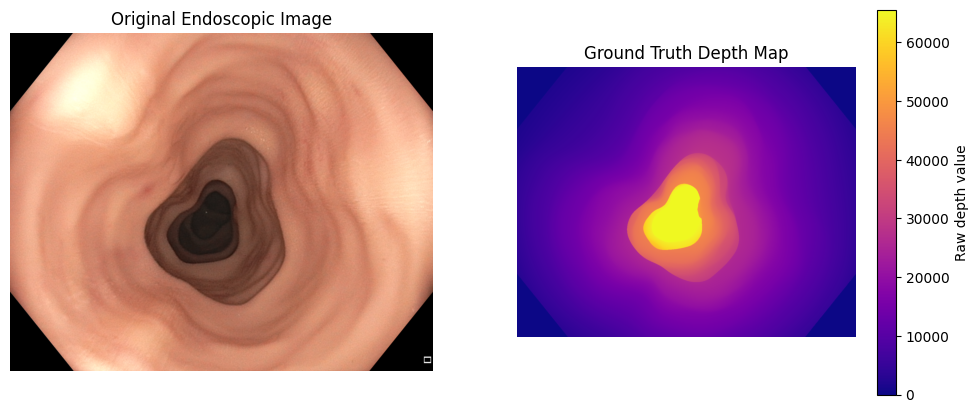

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

folder = "/content/C3VD/trans_t1_a/trans_t1_a"

# Load first RGB image
rgb = cv2.imread(f"{folder}/0001_color.png")
rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

# Load corresponding depth map
depth = cv2.imread(
    f"{folder}/0001_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

print("RGB shape:", rgb.shape)
print("Depth shape:", depth.shape)
print("Depth datatype:", depth.dtype)
print("Depth range:", np.min(depth), np.max(depth))

# Display both
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb)
plt.title("Original Endoscopic Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(depth, cmap="plasma")
plt.title("Ground Truth Depth Map")
plt.colorbar(label="Raw depth value")
plt.axis("off")

plt.show()

Minimum valid depth (mm): 2.4429693
Maximum valid depth (mm): 100.0
Mean valid depth (mm): 25.035471


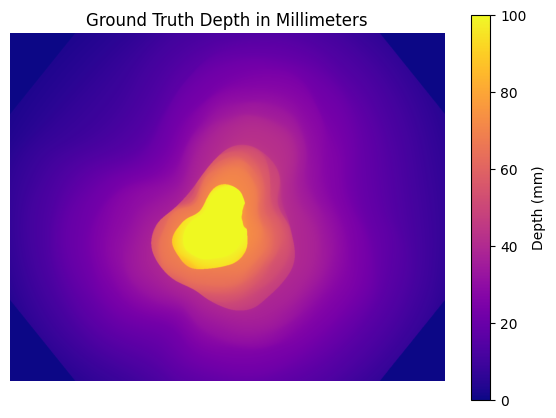

In [10]:
# Convert 16-bit depth to millimeters
depth_mm = depth.astype(np.float32) / 65535.0 * 100.0

# Exclude zero-depth pixels
valid_mask = depth > 0

print("Minimum valid depth (mm):", depth_mm[valid_mask].min())
print("Maximum valid depth (mm):", depth_mm[valid_mask].max())
print("Mean valid depth (mm):", depth_mm[valid_mask].mean())

plt.figure(figsize=(7, 5))
plt.imshow(depth_mm, cmap="plasma", vmin=0, vmax=100)
plt.colorbar(label="Depth (mm)")
plt.title("Ground Truth Depth in Millimeters")
plt.axis("off")
plt.show()

In [11]:
%cd /content

!git clone https://github.com/DepthAnything/Depth-Anything-V2.git

%cd /content/Depth-Anything-V2

/content
Cloning into 'Depth-Anything-V2'...
remote: Enumerating objects: 146, done.
remote: Counting objects: 100% (76/76), done.
remote: Compressing objects: 100% (35/35), done.
remote: Total 146 (delta 45), reused 41 (delta 41), pack-reused 70 (from 1)
Receiving objects: 100% (146/146), 45.17 MiB | 41.56 MiB/s, done.
Resolving deltas: 100% (48/48), done.
/content/Depth-Anything-V2


In [12]:
!pip install -q -r requirements.txt

In [13]:
import os

print("Current directory:", os.getcwd())
print("Model installed:", os.path.exists("depth_anything_v2/dpt.py"))

Current directory: /content/Depth-Anything-V2
Model installed: True


In [14]:
%cd /content/Depth-Anything-V2

!mkdir -p checkpoints

!wget -q --show-progress \
https://huggingface.co/depth-anything/Depth-Anything-V2-Small/resolve/main/depth_anything_v2_vits.pth \
-O checkpoints/depth_anything_v2_vits.pth

/content/Depth-Anything-V2
checkpoints/depth_a 100%[===================>]  94.62M  57.7MB/s    in 1.6s    


In [15]:
import os

model_path = "checkpoints/depth_anything_v2_vits.pth"

print("Weights downloaded:", os.path.exists(model_path))
print("File size (MB):", round(os.path.getsize(model_path) / 1e6, 2))

Weights downloaded: True
File size (MB): 99.22


In [16]:
import torch
from depth_anything_v2.dpt import DepthAnythingV2

# Model configuration
model = DepthAnythingV2(
    encoder='vits',
    features=64,
    out_channels=[48, 96, 192, 384]
)

# Load pretrained weights
model.load_state_dict(
    torch.load(
        'checkpoints/depth_anything_v2_vits.pth',
        map_location='cpu',
        weights_only=True
    )
)

# Move model to GPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'

model = model.to(device).eval()

print("Model loaded successfully!")
print("Running on:", device)
print("Model: Depth Anything V2 Small")

Model loaded successfully!
Running on: cuda
Model: Depth Anything V2 Small


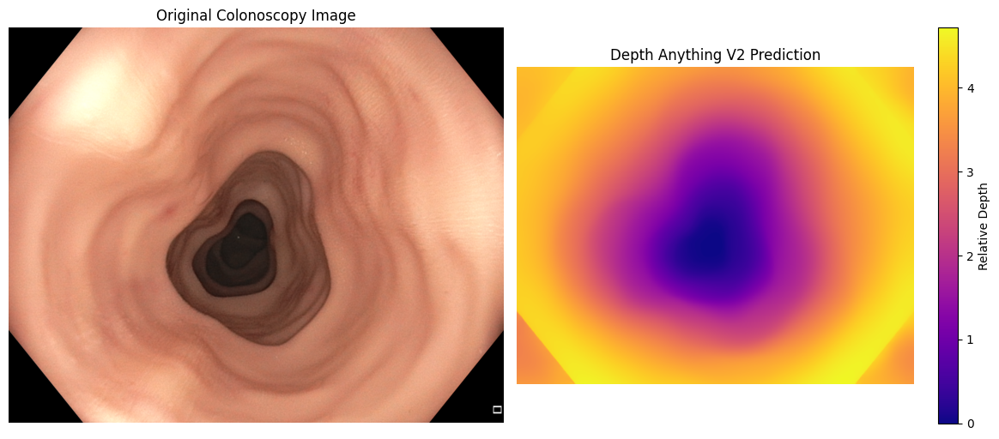

Prediction shape: (1080, 1350)
Minimum prediction: 0.0
Maximum prediction: 4.7171526


In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load C3VD image
image_path = "/content/C3VD/trans_t1_a/trans_t1_a/0001_color.png"

image = cv2.imread(image_path)

# Generate depth prediction
with torch.no_grad():
    predicted_depth = model.infer_image(image, input_size=518)

# Convert image to RGB for display
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display original image and predicted depth
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_image)
plt.title("Original Colonoscopy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(predicted_depth, cmap="plasma")
plt.title("Depth Anything V2 Prediction")
plt.colorbar(label="Relative Depth")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Prediction shape:", predicted_depth.shape)
print("Minimum prediction:", predicted_depth.min())
print("Maximum prediction:", predicted_depth.max())

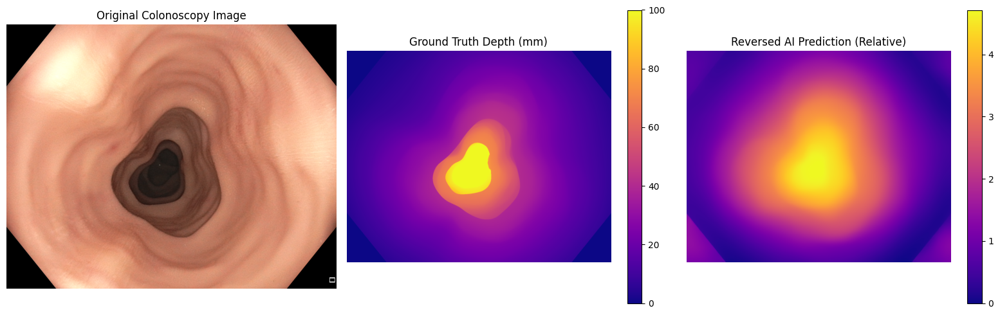

In [18]:
# Reverse relative-depth direction
reversed_depth = predicted_depth.max() - predicted_depth

# Display comparison
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(rgb_image)
plt.title("Original Colonoscopy Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(depth_mm, cmap="plasma")
plt.title("Ground Truth Depth (mm)")
plt.colorbar()
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(reversed_depth, cmap="plasma")
plt.title("Reversed AI Prediction (Relative)")
plt.colorbar()
plt.axis("off")

plt.tight_layout()
plt.show()

Correlation: 0.9091128552648828


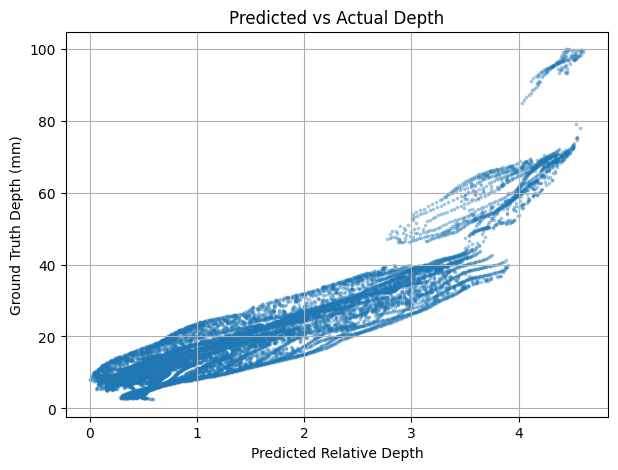

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Select valid ground-truth pixels
valid_mask = (depth > 0) & (depth < 65535)

# Extract corresponding values
gt_values = depth_mm[valid_mask]
pred_values = reversed_depth[valid_mask]

# Calculate correlation
correlation = np.corrcoef(
    gt_values, pred_values
)[0, 1]

print("Correlation:", correlation)

# Plot relationship
plt.figure(figsize=(7, 5))

plt.scatter(
    pred_values[::100],
    gt_values[::100],
    s=3,
    alpha=0.3
)

plt.xlabel("Predicted Relative Depth")
plt.ylabel("Ground Truth Depth (mm)")
plt.title("Predicted vs Actual Depth")
plt.grid(True)
plt.show()

Scale: 13.063408
Offset: 1.3722744


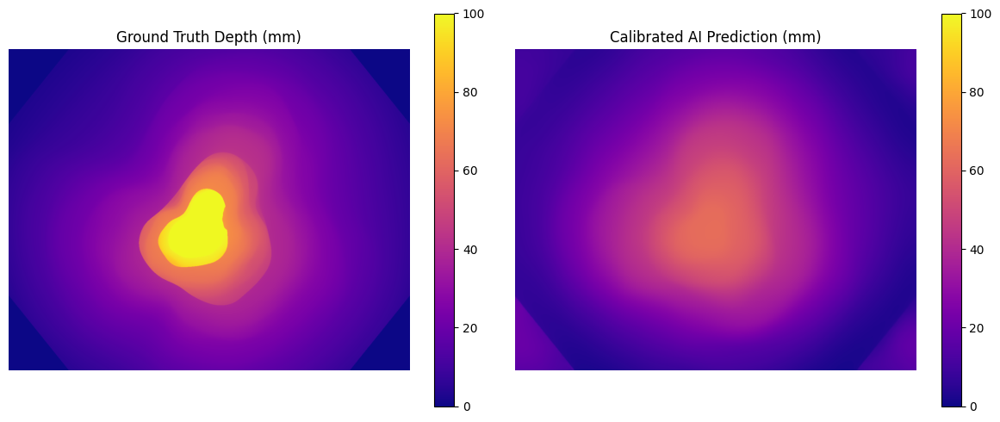

In [20]:
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt

# Use valid pixels from the development image
X = pred_values.reshape(-1, 1)
y = gt_values

# Fit linear calibration
calibrator = LinearRegression()
calibrator.fit(X, y)

# Convert relative depth to millimeters
predicted_depth_mm = calibrator.predict(
    reversed_depth.reshape(-1, 1)
).reshape(reversed_depth.shape)

predicted_depth_mm = np.clip(
    predicted_depth_mm, 0, 100
)

print("Scale:", calibrator.coef_[0])
print("Offset:", calibrator.intercept_)

# Visual comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(depth_mm, cmap="plasma", vmin=0, vmax=100)
plt.title("Ground Truth Depth (mm)")
plt.colorbar()
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(predicted_depth_mm, cmap="plasma", vmin=0, vmax=100)
plt.title("Calibrated AI Prediction (mm)")
plt.colorbar()
plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:
import os
import cv2
import numpy as np
import torch

dev_folder = "/content/C3VD/trans_t1_a/trans_t1_a"
output_folder = "/content/C3VD/dev_predictions"

os.makedirs(output_folder, exist_ok=True)

# Find all RGB images
image_files = sorted([
    f for f in os.listdir(dev_folder)
    if f.endswith("_color.png")
])

print("Total development images:", len(image_files))

# Run Depth Anything V2 on every image
model.eval()

for i, filename in enumerate(image_files):

    image_path = os.path.join(dev_folder, filename)
    image = cv2.imread(image_path)

    if image is None:
        raise RuntimeError(f"Cannot read {image_path}")

    with torch.inference_mode():
        prediction = model.infer_image(image, input_size=518)

    # Save original model output without calibration
    output_name = filename.replace("_color.png", "_pred.npy")

    np.save(
        os.path.join(output_folder, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(image_files):
        print(f"Processed {i + 1}/{len(image_files)} images")

print("All development predictions saved!")

Total development images: 61
Processed 10/61 images
Processed 20/61 images
Processed 30/61 images
Processed 40/61 images
Processed 50/61 images
Processed 60/61 images
Processed 61/61 images
All development predictions saved!


In [22]:
import os
import cv2
import numpy as np
from sklearn.linear_model import LinearRegression

dev_folder = "/content/C3VD/trans_t1_a/trans_t1_a"
output_folder = "/content/C3VD/dev_predictions"

X_all = []
y_all = []

prediction_files = sorted([
    f for f in os.listdir(output_folder)
    if f.endswith("_pred.npy")
])

for filename in prediction_files:

    # Load original AI prediction
    pred = np.load(os.path.join(output_folder, filename))

    # Load corresponding ground-truth depth
    depth_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, depth_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {depth_filename}")

    # Convert ground truth to millimeters
    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Exclude invalid/boundary depth values
    valid = (gt_raw > 0) & (gt_raw < 65535)

    # Use negative prediction because larger model outputs
    # correspond to nearer surfaces in this experiment
    X_all.append((-pred[valid]).reshape(-1, 1))
    y_all.append(gt_mm[valid])

X = np.concatenate(X_all, axis=0)
y = np.concatenate(y_all, axis=0)

# Fit one calibration across all development frames
calibrator = LinearRegression()
calibrator.fit(X, y)

scale = float(calibrator.coef_[0])
offset = float(calibrator.intercept_)

print("Development frames:", len(prediction_files))
print("Total valid pixels:", len(y))
print("Calibration scale:", scale)
print("Calibration offset:", offset)
print("Calibration complete!")

Development frames: 61
Total valid pixels: 80952223
Calibration scale: 13.321044921875
Calibration offset: 64.22636413574219
Calibration complete!


In [23]:
import os
import cv2
import numpy as np

all_absrel = []
all_squared_errors = []
all_delta = []

for filename in prediction_files:

    pred = np.load(os.path.join(output_folder, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")
    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Apply fixed calibration
    pred_mm = -scale * pred + offset
    pred_mm = np.clip(pred_mm, 1e-3, 100.0)

    # Valid depth pixels
    valid = (gt_raw > 0) & (gt_raw < 65535)

    gt = gt_mm[valid]
    prediction = pred_mm[valid]

    # Calculate errors
    all_absrel.append(
        np.mean(np.abs(gt - prediction) / gt)
    )

    all_squared_errors.append(
        np.mean((gt - prediction) ** 2)
    )

    ratio = np.maximum(
        gt / prediction,
        prediction / gt
    )

    all_delta.append(
        np.mean(ratio < 1.25)
    )

print("DEVELOPMENT DATASET RESULTS")
print("---------------------------")
print("AbsRel:", np.mean(all_absrel))
print("RMSE (mm):", np.sqrt(np.mean(all_squared_errors)))
print("Delta < 1.25:", np.mean(all_delta))

DEVELOPMENT DATASET RESULTS
---------------------------
AbsRel: 0.31030893
RMSE (mm): 7.2104206
Delta < 1.25: 0.4524115232610192


In [24]:
import numpy as np

# Calculate median ground-truth depth
# using DEVELOPMENT data only
median_depth = float(np.median(y))

print("Constant median depth (mm):", median_depth)
print("Baseline ready!")

Constant median depth (mm): 17.259479522705078
Baseline ready!


In [25]:
import os
import cv2
import numpy as np
import torch

test_folder = "/content/C3VD/trans_t2_b/trans_t2_b"
test_output = "/content/C3VD/test_predictions"

os.makedirs(test_output, exist_ok=True)

test_files = sorted([
    f for f in os.listdir(test_folder)
    if f.endswith("_color.png")
])

print("Total test images:", len(test_files))

model.eval()

for i, filename in enumerate(test_files):

    image = cv2.imread(
        os.path.join(test_folder, filename)
    )

    if image is None:
        raise RuntimeError(f"Cannot read {filename}")

    with torch.inference_mode():
        prediction = model.infer_image(
            image,
            input_size=518
        )

    output_name = filename.replace(
        "_color.png", "_pred.npy"
    )

    np.save(
        os.path.join(test_output, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(test_files):
        print(f"Processed {i + 1}/{len(test_files)}")

print("All test predictions saved!")

Total test images: 103
Processed 10/103
Processed 20/103
Processed 30/103
Processed 40/103
Processed 50/103
Processed 60/103
Processed 70/103
Processed 80/103
Processed 90/103
Processed 100/103
Processed 103/103
All test predictions saved!


In [26]:
import os
import cv2
import numpy as np

results = {
    "Baseline": {"absrel": [], "sqerr": [], "delta": []},
    "Depth Anything V2": {"absrel": [], "sqerr": [], "delta": []}
}

for filename in sorted(os.listdir(test_output)):
    if not filename.endswith("_pred.npy"):
        continue

    # Load AI prediction
    pred = np.load(os.path.join(test_output, filename))

    # Load ground-truth depth
    gt_filename = filename.replace("_pred.npy", "_depth.tiff")
    gt_raw = cv2.imread(
        os.path.join(test_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {gt_filename}")

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Provisional valid-depth mask
    valid = (gt_raw > 0) & (gt_raw < 65535)

    gt = gt_mm[valid]

    # Model 1: Constant-median baseline
    baseline = np.full_like(gt, median_depth)

    # Model 2: Depth Anything V2
    calibrated = -scale * pred + offset
    calibrated = np.clip(calibrated, 1e-3, 100.0)
    ai = calibrated[valid]

    for name, prediction in [
        ("Baseline", baseline),
        ("Depth Anything V2", ai)
    ]:
        results[name]["absrel"].append(
            np.mean(np.abs(gt - prediction) / gt)
        )

        results[name]["sqerr"].append(
            np.mean((gt - prediction) ** 2)
        )

        ratio = np.maximum(
            gt / prediction,
            prediction / gt
        )

        results[name]["delta"].append(
            np.mean(ratio < 1.25)
        )

print("FINAL TEST COMPARISON")
print("-" * 65)
print(f"{'Model':<22} {'AbsRel':<12} {'RMSE (mm)':<12} {'Delta < 1.25'}")

for name, values in results.items():
    absrel = np.mean(values["absrel"])
    rmse = np.sqrt(np.mean(values["sqerr"]))
    delta = np.mean(values["delta"])

    print(f"{name:<22} {absrel:<12.4f} {rmse:<12.4f} {delta:.4f}")

FINAL TEST COMPARISON
-----------------------------------------------------------------
Model                  AbsRel       RMSE (mm)    Delta < 1.25
Baseline               0.5499       17.7102      0.2752
Depth Anything V2      0.3323       7.1045       0.4587


In [27]:
import os
import shutil
import json

save_folder = "/content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2"

os.makedirs(save_folder, exist_ok=True)

# Save development and test predictions
shutil.copytree(
    "/content/C3VD/dev_predictions",
    f"{save_folder}/dev_predictions",
    dirs_exist_ok=True
)

shutil.copytree(
    "/content/C3VD/test_predictions",
    f"{save_folder}/test_predictions",
    dirs_exist_ok=True
)

# Save calibration and baseline parameters
parameters = {
    "model": "Depth Anything V2 Small",
    "development_sequence": "trans_t1_a",
    "test_sequence": "trans_t2_b",
    "scale": float(scale),
    "offset": float(offset),
    "median_depth_mm": float(median_depth),
    "input_size": 518
}

with open(f"{save_folder}/parameters.json", "w") as f:
    json.dump(parameters, f, indent=4)

print("All results saved to Google Drive!")
print("Location:", save_folder)

All results saved to Google Drive!
Location: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2


In [28]:
import cv2
import numpy as np

folder = "/content/C3VD/trans_t1_a/trans_t1_a"

gt_raw = cv2.imread(
    f"{folder}/0001_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

total = gt_raw.size

zero_pixels = np.sum(gt_raw == 0)
max_pixels = np.sum(gt_raw == 65535)
other_pixels = np.sum((gt_raw > 0) & (gt_raw < 65535))

print("Depth datatype:", gt_raw.dtype)
print("Total pixels:", total)

print("\nPixel distribution:")
print("Zero pixels:", zero_pixels)
print("65535 pixels:", max_pixels)
print("Other pixels:", other_pixels)

print("\nPercentages:")
print("Zero pixels:", round(zero_pixels / total * 100, 2), "%")
print("65535 pixels:", round(max_pixels / total * 100, 2), "%")
print("Other pixels:", round(other_pixels / total * 100, 2), "%")

print("\nDepth percentiles (raw values):")
print(np.percentile(gt_raw, [0, 1, 25, 50, 75, 99, 100]))

Depth datatype: uint16
Total pixels: 1458000

Pixel distribution:
Zero pixels: 102049
65535 pixels: 28974
Other pixels: 1326977

Percentages:
Zero pixels: 7.0 %
65535 pixels: 1.99 %
Other pixels: 91.01 %

Depth percentiles (raw values):
[    0.     0.  6618. 11887. 19491. 65535. 65535.]


In [29]:
import os
import cv2
import numpy as np

results_new = {
    "Baseline": {"absrel": [], "sqerr": [], "delta": []},
    "Depth Anything V2": {"absrel": [], "sqerr": [], "delta": []}
}

for filename in sorted(os.listdir(test_output)):

    if not filename.endswith("_pred.npy"):
        continue

    pred = np.load(os.path.join(test_output, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(test_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Include 65535 (100 mm), exclude zero
    valid = gt_raw > 0

    gt = gt_mm[valid]

    baseline = np.full_like(gt, median_depth)

    calibrated = np.clip(
        -scale * pred + offset,
        1e-3,
        100.0
    )

    ai = calibrated[valid]

    for name, prediction in [
        ("Baseline", baseline),
        ("Depth Anything V2", ai)
    ]:

        results_new[name]["absrel"].append(
            np.mean(np.abs(gt - prediction) / gt)
        )

        results_new[name]["sqerr"].append(
            np.mean((gt - prediction) ** 2)
        )

        ratio = np.maximum(
            gt / prediction,
            prediction / gt
        )

        results_new[name]["delta"].append(
            np.mean(ratio < 1.25)
        )

print("TEST RESULTS INCLUDING 100 mm PIXELS")
print("-" * 65)

for name, values in results_new.items():

    absrel = np.mean(values["absrel"])
    rmse = np.sqrt(np.mean(values["sqerr"]))
    delta = np.mean(values["delta"])

    print(
        f"{name}: AbsRel={absrel:.4f}, "
        f"RMSE={rmse:.4f} mm, "
        f"Delta={delta:.4f}"
    )

TEST RESULTS INCLUDING 100 mm PIXELS
-----------------------------------------------------------------
Baseline: AbsRel=0.5559, RMSE=21.3165 mm, Delta=0.2693
Depth Anything V2: AbsRel=0.3334, RMSE=8.9634 mm, Delta=0.4488


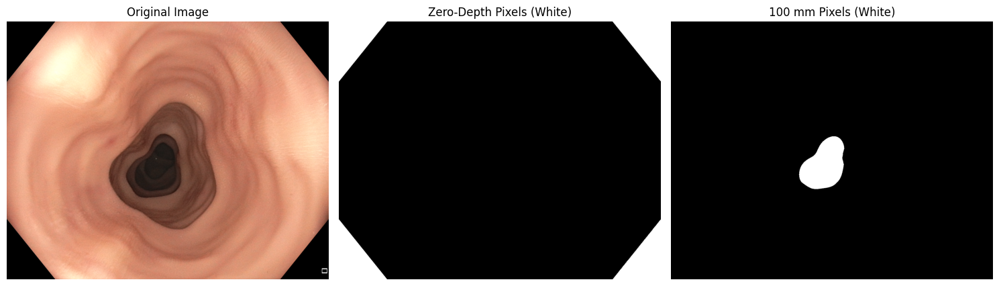

In [30]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

folder = "/content/C3VD/trans_t1_a/trans_t1_a"

rgb = cv2.cvtColor(
    cv2.imread(f"{folder}/0001_color.png"),
    cv2.COLOR_BGR2RGB
)

gt_raw = cv2.imread(
    f"{folder}/0001_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

zero_mask = gt_raw == 0
max_mask = gt_raw == 65535

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(zero_mask, cmap="gray")
plt.title("Zero-Depth Pixels (White)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(max_mask, cmap="gray")
plt.title("100 mm Pixels (White)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [31]:
import os
import cv2
import numpy as np
from sklearn.linear_model import LinearRegression

X_all = []
y_all = []

for filename in prediction_files:
    pred = np.load(os.path.join(output_folder, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")
    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Final evaluation mask
    valid = gt_raw > 0

    X_all.append((-pred[valid]).reshape(-1, 1))
    y_all.append(gt_mm[valid])

X = np.concatenate(X_all)
y = np.concatenate(y_all)

calibrator = LinearRegression()
calibrator.fit(X, y)

scale = float(calibrator.coef_[0])
offset = float(calibrator.intercept_)
median_depth = float(np.median(y))

print("Updated scale:", scale)
print("Updated offset:", offset)
print("Updated median baseline (mm):", median_depth)
print("Total valid development pixels:", len(y))

Updated scale: 14.802687644958496
Updated offset: 69.5309829711914
Updated median baseline (mm): 17.582971572875977
Total valid development pixels: 82713011


In [32]:
import os
import cv2
import numpy as np

results_final = {
    "Baseline": {"absrel": [], "sqerr": [], "delta": []},
    "Depth Anything V2": {"absrel": [], "sqerr": [], "delta": []}
}

test_files = sorted([
    f for f in os.listdir(test_output)
    if f.endswith("_pred.npy")
])

for filename in test_files:

    # Load model prediction
    pred = np.load(os.path.join(test_output, filename))

    # Load ground-truth depth
    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(test_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {gt_filename}")

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Consistent evaluation mask
    valid = gt_raw > 0
    gt = gt_mm[valid]

    # Constant-median baseline
    baseline = np.full_like(gt, median_depth)

    # Depth Anything V2 calibrated prediction
    calibrated = np.clip(
        -scale * pred + offset,
        1e-3,
        100.0
    )
    ai = calibrated[valid]

    for name, prediction in [
        ("Baseline", baseline),
        ("Depth Anything V2", ai)
    ]:
        results_final[name]["absrel"].append(
            np.mean(np.abs(gt - prediction) / gt)
        )

        results_final[name]["sqerr"].append(
            np.mean((gt - prediction) ** 2)
        )

        ratio = np.maximum(
            gt / prediction,
            prediction / gt
        )

        results_final[name]["delta"].append(
            np.mean(ratio < 1.25)
        )

print("UPDATED TEST RESULTS")
print("-" * 65)
print(f"{'Model':<22} {'AbsRel':<12} {'RMSE (mm)':<12} {'Delta < 1.25'}")

for name, values in results_final.items():
    absrel = np.mean(values["absrel"])
    rmse = np.sqrt(np.mean(values["sqerr"]))
    delta = np.mean(values["delta"])

    print(f"{name:<22} {absrel:<12.4f} {rmse:<12.4f} {delta:.4f}")

UPDATED TEST RESULTS
-----------------------------------------------------------------
Model                  AbsRel       RMSE (mm)    Delta < 1.25
Baseline               0.5655       21.2086      0.2704
Depth Anything V2      0.3700       8.7136       0.4162


In [33]:
import os
import json
import pandas as pd

save_folder = "/content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2"
os.makedirs(save_folder, exist_ok=True)

# Save updated calibration
parameters = {
    "model": "Depth Anything V2 Small",
    "development_sequence": "trans_t1_a",
    "test_sequence": "trans_t2_b",
    "scale": float(scale),
    "offset": float(offset),
    "median_depth_mm": float(median_depth),
    "input_size": 518,
    "valid_depth_mask": "gt_raw > 0",
    "depth_range_mm": [0, 100]
}

with open(f"{save_folder}/parameters.json", "w") as f:
    json.dump(parameters, f, indent=4)

# Save evaluation results
rows = []

for name, values in results_final.items():
    rows.append({
        "Model": name,
        "AbsRel": float(np.mean(values["absrel"])),
        "RMSE_mm": float(np.sqrt(np.mean(values["sqerr"]))),
        "Delta_1.25": float(np.mean(values["delta"]))
    })

df = pd.DataFrame(rows)
df.to_csv(f"{save_folder}/test_results.csv", index=False)

print("Updated parameters and results saved!")
print(df.to_string(index=False))

Updated parameters and results saved!
            Model   AbsRel   RMSE_mm  Delta_1.25
         Baseline 0.565481 21.208551    0.270393
Depth Anything V2 0.370023  8.713642    0.416236


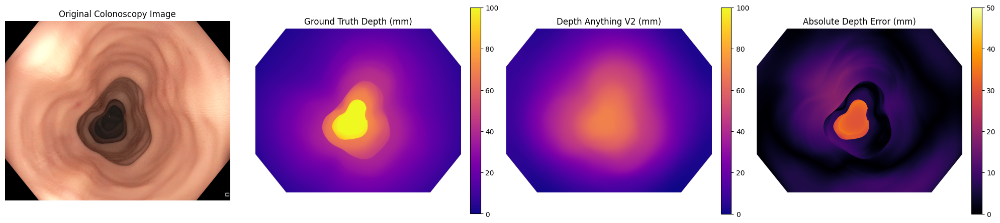

Figure saved to: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/depth_comparison.png
Mean Absolute Error (mm): 6.204653


In [34]:

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use a development image for visualization
frame = "0001"

folder = "/content/C3VD/trans_t1_a/trans_t1_a"
pred_folder = "/content/C3VD/dev_predictions"

# Load original image
rgb = cv2.imread(f"{folder}/{frame}_color.png")
rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

# Load ground truth
gt_raw = cv2.imread(
    f"{folder}/{frame}_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

# Load saved model prediction
pred = np.load(f"{pred_folder}/{frame}_pred.npy")

# Apply development-set calibration
pred_mm = np.clip(
    -scale * pred + offset,
    1e-3,
    100.0
)

# Valid pixels
valid = gt_raw > 0

# Absolute depth error
error = np.abs(gt_mm - pred_mm)
error[~valid] = np.nan

# Hide invalid pixels in depth maps
gt_display = np.where(valid, gt_mm, np.nan)
pred_display = np.where(valid, pred_mm, np.nan)

# Create comparison figure
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(rgb)
axes[0].set_title("Original Colonoscopy Image")

im1 = axes[1].imshow(
    gt_display, cmap="plasma", vmin=0, vmax=100
)
axes[1].set_title("Ground Truth Depth (mm)")

im2 = axes[2].imshow(
    pred_display, cmap="plasma", vmin=0, vmax=100
)
axes[2].set_title("Depth Anything V2 (mm)")

im3 = axes[3].imshow(
    error, cmap="inferno", vmin=0, vmax=50
)
axes[3].set_title("Absolute Depth Error (mm)")

for ax in axes:
    ax.axis("off")

fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)
fig.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

plt.tight_layout()

# CORRECTED: Save to your Google Drive project folder
save_folder = (
    "/content/drive/MyDrive/"
    "BN5211_Depth_Project/"
    "DepthAnythingV2"
)

os.makedirs(save_folder, exist_ok=True)

save_path = os.path.join(
    save_folder,
    "depth_comparison.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", save_path)
print("Mean Absolute Error (mm):", np.nanmean(error))


0–20 mm: MAE = 4.828 mm, Pixels = 47315777
20–40 mm: MAE = 7.096 mm, Pixels = 21834912
40–60 mm: MAE = 5.265 mm, Pixels = 7681999
60–100 mm: MAE = 19.431 mm, Pixels = 5880323


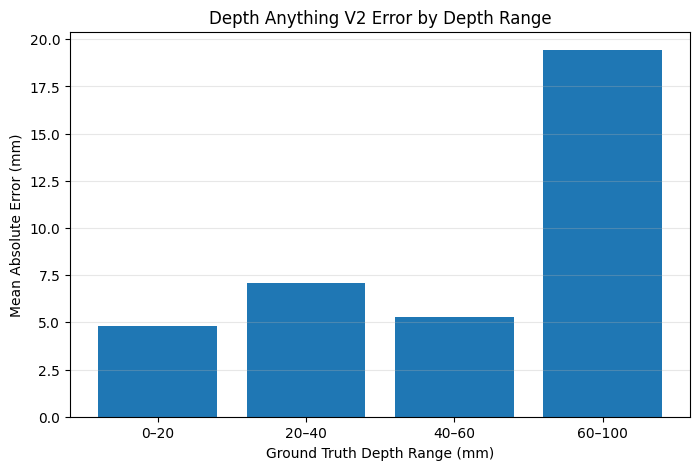

In [35]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

depth_ranges = [(0, 20), (20, 40), (40, 60), (60, 100)]

error_sums = np.zeros(4, dtype=np.float64)
pixel_counts = np.zeros(4, dtype=np.int64)

for filename in prediction_files:

    pred = np.load(os.path.join(output_folder, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    pred_mm = np.clip(
        -scale * pred + offset,
        1e-3,
        100.0
    )

    valid = gt_raw > 0
    error = np.abs(gt_mm - pred_mm)

    for i, (low, high) in enumerate(depth_ranges):

        if high == 100:
            mask = valid & (gt_mm >= low) & (gt_mm <= high)
        else:
            mask = valid & (gt_mm >= low) & (gt_mm < high)

        error_sums[i] += np.sum(error[mask], dtype=np.float64)
        pixel_counts[i] += np.count_nonzero(mask)

mae_by_range = error_sums / np.maximum(pixel_counts, 1)

labels = ["0–20", "20–40", "40–60", "60–100"]

for label, mae, count in zip(labels, mae_by_range, pixel_counts):
    print(f"{label} mm: MAE = {mae:.3f} mm, Pixels = {count}")

plt.figure(figsize=(8, 5))
plt.bar(labels, mae_by_range)
plt.xlabel("Ground Truth Depth Range (mm)")
plt.ylabel("Mean Absolute Error (mm)")
plt.title("Depth Anything V2 Error by Depth Range")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [36]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# X and y were created from all development frames in Step 27
# X = negative raw model predictions
# y = ground-truth depth in millimeters

# Use a sample to reduce computation
rng = np.random.default_rng(42)
sample_size = min(500000, len(y))

indices = rng.choice(
    len(y),
    size=sample_size,
    replace=False
)

X_sample = X[indices]
y_sample = y[indices]

# Create second-degree polynomial features
poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_poly = poly.fit_transform(X_sample)

# Train nonlinear calibration
poly_model = LinearRegression()
poly_model.fit(X_poly, y_sample)

print("Polynomial coefficients:", poly_model.coef_)
print("Intercept:", poly_model.intercept_)
print("Polynomial calibration trained successfully!")

Polynomial coefficients: [ 0.44736296 -2.4325354 ]
Intercept: 52.119026
Polynomial calibration trained successfully!


In [37]:
import os
import cv2
import numpy as np

comparison = {
    "Linear": {"absrel": [], "sqerr": [], "delta": []},
    "Polynomial": {"absrel": [], "sqerr": [], "delta": []}
}

for filename in prediction_files:

    # Load saved prediction
    pred = np.load(os.path.join(output_folder, filename))

    # Load ground-truth depth
    gt_filename = filename.replace("_pred.npy", "_depth.tiff")
    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0
    valid = gt_raw > 0

    # Original linear calibration
    linear_depth = np.clip(
        -scale * pred + offset,
        1e-3, 100.0
    )

    # New polynomial calibration
    # Coefficients correspond to P and P^2, where P = -pred
    p = -pred
    a, b = poly_model.coef_

    polynomial_depth = np.clip(
        a * p + b * p**2 + poly_model.intercept_,
        1e-3, 100.0
    )

    gt = gt_mm[valid]

    for name, prediction_map in [
        ("Linear", linear_depth),
        ("Polynomial", polynomial_depth)
    ]:
        prediction = prediction_map[valid]

        comparison[name]["absrel"].append(
            np.mean(np.abs(gt - prediction) / gt)
        )

        comparison[name]["sqerr"].append(
            np.mean((gt - prediction) ** 2)
        )

        ratio = np.maximum(
            gt / prediction,
            prediction / gt
        )

        comparison[name]["delta"].append(
            np.mean(ratio < 1.25)
        )

print("DEVELOPMENT DATASET COMPARISON")
print("-" * 65)

for name, values in comparison.items():
    print(
        f"{name}: "
        f"AbsRel={np.mean(values['absrel']):.4f}, "
        f"RMSE={np.sqrt(np.mean(values['sqerr'])):.4f} mm, "
        f"Delta={np.mean(values['delta']):.4f}"
    )

DEVELOPMENT DATASET COMPARISON
-----------------------------------------------------------------
Linear: AbsRel=0.3425, RMSE=8.7923 mm, Delta=0.4043
Polynomial: AbsRel=0.4304, RMSE=11.7330 mm, Delta=0.3227


In [38]:

%pip install -q --upgrade opencv-contrib-python-headless


In [39]:

import cv2

print("OpenCV version:", cv2.__version__)
print("ximgproc available:", hasattr(cv2, "ximgproc"))
print(
    "jointBilateralFilter available:",
    hasattr(
        getattr(cv2, "ximgproc", None),
        "jointBilateralFilter"
    )
)


OpenCV version: 4.14.0
ximgproc available: True
jointBilateralFilter available: True


Original MAE: 5.643664 mm
Refined MAE: 5.643242 mm


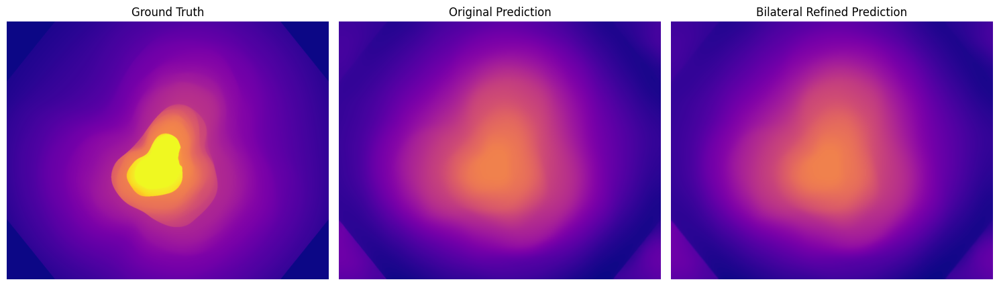

In [40]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

frame = "0001"

folder = "/content/C3VD/trans_t1_a/trans_t1_a"
pred_folder = "/content/C3VD/dev_predictions"

rgb = cv2.imread(f"{folder}/{frame}_color.png")
if rgb is None:
    raise FileNotFoundError("RGB image not found")

pred = np.load(f"{pred_folder}/{frame}_pred.npy")

linear_depth = np.clip(
    -scale * pred + offset,
    1e-3, 100.0
).astype(np.float32)

# Standard bilateral filter (does not require ximgproc)
refined_depth = cv2.bilateralFilter(
    linear_depth,
    d=9,
    sigmaColor=25,
    sigmaSpace=5
)

gt_raw = cv2.imread(
    f"{folder}/{frame}_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

if gt_raw is None:
    raise FileNotFoundError("Ground-truth depth not found")

gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0
valid = (gt_raw > 0) & (gt_raw < 65535)

original_mae = np.mean(
    np.abs(gt_mm[valid] - linear_depth[valid])
)

refined_mae = np.mean(
    np.abs(gt_mm[valid] - refined_depth[valid])
)

print(f"Original MAE: {original_mae:.6f} mm")
print(f"Refined MAE: {refined_mae:.6f} mm")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(gt_mm, cmap="plasma", vmin=0, vmax=100)
axes[0].set_title("Ground Truth")

axes[1].imshow(linear_depth, cmap="plasma", vmin=0, vmax=100)
axes[1].set_title("Original Prediction")

axes[2].imshow(refined_depth, cmap="plasma", vmin=0, vmax=100)
axes[2].set_title("Bilateral Refined Prediction")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


BILATERAL FILTER COMPARISON
-------------------------------------------------------
d=9, sigmaColor=25, sigmaSpace=5: MAE=5.643242 mm
d=15, sigmaColor=50, sigmaSpace=10: MAE=5.642543 mm
d=25, sigmaColor=75, sigmaSpace=15: MAE=5.640661 mm

Original MAE: 5.643664 mm


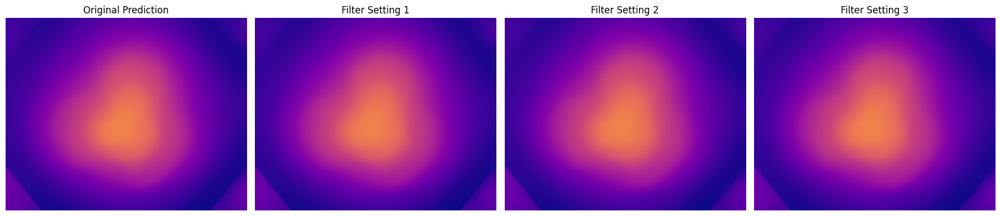

In [41]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

settings = [
    (9, 25, 5),
    (15, 50, 10),
    (25, 75, 15)
]

print("BILATERAL FILTER COMPARISON")
print("-" * 55)

filtered_maps = []

for d, sigma_color, sigma_space in settings:

    refined = cv2.bilateralFilter(
        linear_depth.astype(np.float32),
        d=d,
        sigmaColor=sigma_color,
        sigmaSpace=sigma_space
    )

    mae = np.mean(
        np.abs(gt_mm[valid] - refined[valid])
    )

    filtered_maps.append(refined)

    print(
        f"d={d}, sigmaColor={sigma_color}, "
        f"sigmaSpace={sigma_space}: MAE={mae:.6f} mm"
    )

print(f"\nOriginal MAE: {original_mae:.6f} mm")

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(linear_depth, cmap="plasma", vmin=0, vmax=100)
axes[0].set_title("Original Prediction")

for i, refined in enumerate(filtered_maps):
    axes[i + 1].imshow(
        refined, cmap="plasma", vmin=0, vmax=100
    )
    axes[i + 1].set_title(f"Filter Setting {i + 1}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


MEAN SIGNED DEPTH ERROR
------------------------
0–20 mm: 0.123 mm
20–40 mm: -4.550 mm
40–60 mm: -2.981 mm
60–100 mm: 19.417 mm


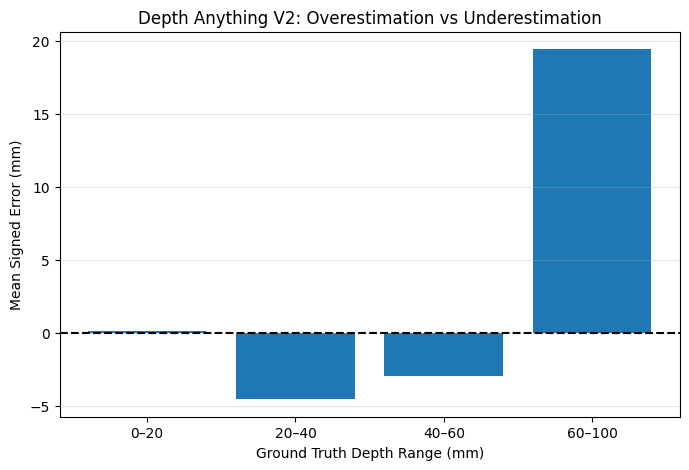

In [42]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

depth_ranges = [(0, 20), (20, 40), (40, 60), (60, 100)]

error_sums = np.zeros(4)
pixel_counts = np.zeros(4)

for filename in prediction_files:

    pred = np.load(os.path.join(output_folder, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    pred_mm = np.clip(
        -scale * pred + offset,
        1e-3,
        100.0
    )

    valid = gt_raw > 0

    # Signed error: positive means underestimation
    signed_error = gt_mm - pred_mm

    for i, (low, high) in enumerate(depth_ranges):

        if high == 100:
            mask = valid & (gt_mm >= low) & (gt_mm <= high)
        else:
            mask = valid & (gt_mm >= low) & (gt_mm < high)

        error_sums[i] += np.sum(
            signed_error[mask], dtype=np.float64
        )

        pixel_counts[i] += np.count_nonzero(mask)

mean_signed_errors = error_sums / pixel_counts

labels = ["0–20", "20–40", "40–60", "60–100"]

print("MEAN SIGNED DEPTH ERROR")
print("------------------------")

for label, error in zip(labels, mean_signed_errors):
    print(f"{label} mm: {error:.3f} mm")

plt.figure(figsize=(8, 5))
plt.bar(labels, mean_signed_errors)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Ground Truth Depth Range (mm)")
plt.ylabel("Mean Signed Error (mm)")
plt.title("Depth Anything V2: Overestimation vs Underestimation")
plt.grid(axis="y", alpha=0.3)
plt.show()

ERROR BY PREDICTED DEPTH
---------------------------------------------
0–20 mm: Signed Error = 1.852 mm, Pixels = 42761235
20–40 mm: Signed Error = -5.170 mm, Pixels = 21284495
40–60 mm: Signed Error = -5.013 mm, Pixels = 13919401
60–80 mm: Signed Error = 20.718 mm, Pixels = 4747880
80–100 mm: Signed Error = nan mm, Pixels = 0


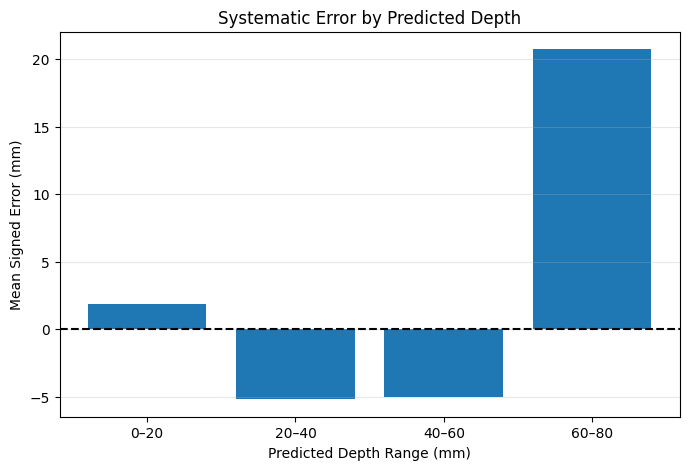

In [43]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Predicted-depth intervals
bins = [0, 20, 40, 60, 80, 100]

error_sums = np.zeros(5, dtype=np.float64)
pixel_counts = np.zeros(5, dtype=np.int64)

for filename in prediction_files:

    pred = np.load(
        os.path.join(output_folder, filename)
    )

    gt_filename = filename.replace(
        "_pred.npy", "_depth.tiff"
    )

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    pred_mm = np.clip(
        -scale * pred + offset,
        1e-3, 100.0
    )

    valid = gt_raw > 0

    signed_error = gt_mm - pred_mm

    for i in range(len(bins) - 1):

        low = bins[i]
        high = bins[i + 1]

        if high == 100:
            mask = valid & (pred_mm >= low) & (pred_mm <= high)
        else:
            mask = valid & (pred_mm >= low) & (pred_mm < high)

        error_sums[i] += np.sum(
            signed_error[mask],
            dtype=np.float64
        )

        pixel_counts[i] += np.count_nonzero(mask)

mean_errors = np.divide(
    error_sums,
    pixel_counts,
    out=np.full(5, np.nan),
    where=pixel_counts > 0
)

labels = ["0–20", "20–40", "40–60", "60–80", "80–100"]

print("ERROR BY PREDICTED DEPTH")
print("-" * 45)

for label, error, count in zip(
    labels, mean_errors, pixel_counts
):
    print(
        f"{label} mm: "
        f"Signed Error = {error:.3f} mm, "
        f"Pixels = {count}"
    )

plt.figure(figsize=(8, 5))
plt.bar(labels, mean_errors)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Predicted Depth Range (mm)")
plt.ylabel("Mean Signed Error (mm)")
plt.title("Systematic Error by Predicted Depth")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [44]:
import os
import numpy as np

# Existing saved predictions from trans_t1_a
all_files = sorted([
    f for f in os.listdir(output_folder)
    if f.endswith("_pred.npy")
])

train_files = all_files[:45]
val_files = all_files[45:]

print("Training frames:", len(train_files))
print("Validation frames:", len(val_files))

print("\nTraining:")
print(train_files[0], "to", train_files[-1])

print("\nValidation:")
print(val_files[0], "to", val_files[-1])

Training frames: 45
Validation frames: 16

Training:
0000_pred.npy to 0044_pred.npy

Validation:
0045_pred.npy to 0060_pred.npy


In [45]:
import os
import cv2
import numpy as np
from sklearn.linear_model import LinearRegression

X_train = []
y_train = []

for filename in train_files:

    # Load saved Depth Anything V2 prediction
    pred = np.load(
        os.path.join(output_folder, filename)
    )

    # Load corresponding ground-truth depth
    gt_filename = filename.replace(
        "_pred.npy", "_depth.tiff"
    )

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    # Convert depth to millimeters
    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Exclude zero-depth background
    valid = gt_raw > 0

    # Use negative raw prediction
    X_train.append((-pred[valid]).reshape(-1, 1))
    y_train.append(gt_mm[valid])

# Combine training data
X_train = np.concatenate(X_train)
y_train = np.concatenate(y_train)

# Train linear calibration
linear_train_model = LinearRegression()
linear_train_model.fit(X_train, y_train)

train_scale = float(linear_train_model.coef_[0])
train_offset = float(linear_train_model.intercept_)

print("TRAINING-ONLY LINEAR CALIBRATION")
print("--------------------------------")
print("Training frames:", len(train_files))
print("Training pixels:", len(y_train))
print("Scale:", train_scale)
print("Offset:", train_offset)
print("Training completed!")

TRAINING-ONLY LINEAR CALIBRATION
--------------------------------
Training frames: 45
Training pixels: 61017795
Scale: 14.583353042602539
Offset: 68.20346069335938
Training completed!


In [46]:
import numpy as np

# Predicted-depth intervals in millimeters
bins = np.array([0, 20, 40, 60, 80, 100])

# Apply training-only linear calibration
train_pred_mm = np.clip(
    train_scale * X_train[:, 0] + train_offset,
    1e-3,
    100.0
)

# Calculate signed errors
train_errors = y_train - train_pred_mm

# Learn correction for each predicted-depth range
corrections = []
counts = []

for i in range(len(bins) - 1):

    low = bins[i]
    high = bins[i + 1]

    if high == 100:
        mask = (train_pred_mm >= low) & (train_pred_mm <= high)
    else:
        mask = (train_pred_mm >= low) & (train_pred_mm < high)

    count = np.count_nonzero(mask)

    if count > 0:
        correction = float(np.mean(train_errors[mask]))
    else:
        correction = 0.0

    corrections.append(correction)
    counts.append(count)

print("LEARNED DEPTH CORRECTIONS")
print("-" * 55)

for i in range(len(corrections)):
    print(
        f"{bins[i]}-{bins[i+1]} mm: "
        f"Correction = {corrections[i]:.3f} mm, "
        f"Pixels = {counts[i]}"
    )

print("\nBias correction model trained successfully!")

LEARNED DEPTH CORRECTIONS
-------------------------------------------------------
0-20 mm: Correction = 1.857 mm, Pixels = 30700131
20-40 mm: Correction = -5.211 mm, Pixels = 16355948
40-60 mm: Correction = -4.206 mm, Pixels = 10902135
60-80 mm: Correction = 23.373 mm, Pixels = 3059581
80-100 mm: Correction = 0.000 mm, Pixels = 0

Bias correction model trained successfully!


In [47]:
import os
import cv2
import numpy as np

validation_results = {
    "Linear": {"absrel": [], "sqerr": [], "delta": []},
    "Bias Corrected": {"absrel": [], "sqerr": [], "delta": []}
}

for filename in val_files:

    pred = np.load(os.path.join(output_folder, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0
    valid = gt_raw > 0

    # Linear calibration trained on 45 frames
    linear_depth = np.clip(
        -train_scale * pred + train_offset,
        1e-3, 100.0
    )

    # Apply learned depth-dependent correction
    corrected_depth = linear_depth.copy()

    for i in range(len(bins) - 1):
        low, high = bins[i], bins[i + 1]

        if high == 100:
            mask = (linear_depth >= low) & (linear_depth <= high)
        else:
            mask = (linear_depth >= low) & (linear_depth < high)

        corrected_depth[mask] += corrections[i]

    corrected_depth = np.clip(
        corrected_depth, 1e-3, 100.0
    )

    gt = gt_mm[valid]

    for name, depth_map in [
        ("Linear", linear_depth),
        ("Bias Corrected", corrected_depth)
    ]:
        prediction = depth_map[valid]

        validation_results[name]["absrel"].append(
            np.mean(np.abs(gt - prediction) / gt)
        )

        validation_results[name]["sqerr"].append(
            np.mean((gt - prediction) ** 2)
        )

        ratio = np.maximum(
            gt / prediction,
            prediction / gt
        )

        validation_results[name]["delta"].append(
            np.mean(ratio < 1.25)
        )

print("VALIDATION RESULTS — 16 FRAMES")
print("-" * 65)

for name, values in validation_results.items():
    print(
        f"{name}: "
        f"AbsRel={np.mean(values['absrel']):.4f}, "
        f"RMSE={np.sqrt(np.mean(values['sqerr'])):.4f} mm, "
        f"Delta={np.mean(values['delta']):.4f}"
    )

VALIDATION RESULTS — 16 FRAMES
-----------------------------------------------------------------
Linear: AbsRel=0.3128, RMSE=8.4090 mm, Delta=0.4395
Bias Corrected: AbsRel=0.2686, RMSE=6.1306 mm, Delta=0.5137


Original MAE: 5.7090025
Corrected MAE: 4.7585278


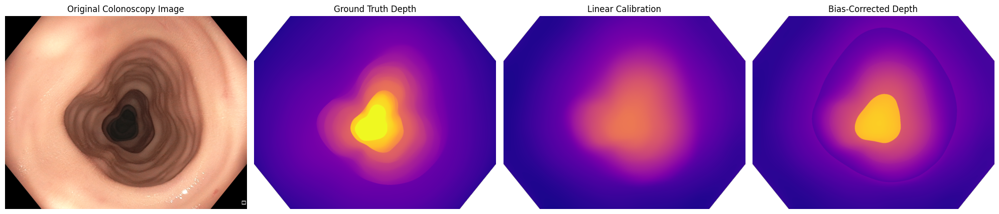

In [48]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# First validation frame
frame = "0045"

folder = "/content/C3VD/trans_t1_a/trans_t1_a"
pred_folder = "/content/C3VD/dev_predictions"

rgb = cv2.imread(f"{folder}/{frame}_color.png")
rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

gt_raw = cv2.imread(
    f"{folder}/{frame}_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0
valid = gt_raw > 0

pred = np.load(f"{pred_folder}/{frame}_pred.npy")

# Original linear prediction
linear_depth = np.clip(
    -train_scale * pred + train_offset,
    1e-3, 100.0
)

# Apply bias correction
corrected_depth = linear_depth.copy()

for i in range(len(bins) - 1):
    low, high = bins[i], bins[i + 1]

    if high == 100:
        mask = (linear_depth >= low) & (linear_depth <= high)
    else:
        mask = (linear_depth >= low) & (linear_depth < high)

    corrected_depth[mask] += corrections[i]

corrected_depth = np.clip(corrected_depth, 1e-3, 100.0)

# Calculate absolute errors
linear_error = np.abs(gt_mm - linear_depth)
corrected_error = np.abs(gt_mm - corrected_depth)

print("Original MAE:", np.mean(linear_error[valid]))
print("Corrected MAE:", np.mean(corrected_error[valid]))

# Display results
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

images = [
    rgb,
    np.where(valid, gt_mm, np.nan),
    np.where(valid, linear_depth, np.nan),
    np.where(valid, corrected_depth, np.nan)
]

titles = [
    "Original Colonoscopy Image",
    "Ground Truth Depth",
    "Linear Calibration",
    "Bias-Corrected Depth"
]

for i, ax in enumerate(axes):
    if i == 0:
        ax.imshow(images[i])
    else:
        ax.imshow(images[i], cmap="plasma", vmin=0, vmax=100)

    ax.set_title(titles[i])
    ax.axis("off")

plt.tight_layout()
plt.show()

Original MAE: 5.7090025
Piecewise corrected MAE: 4.7585278
Smooth corrected MAE: 4.49686470979312


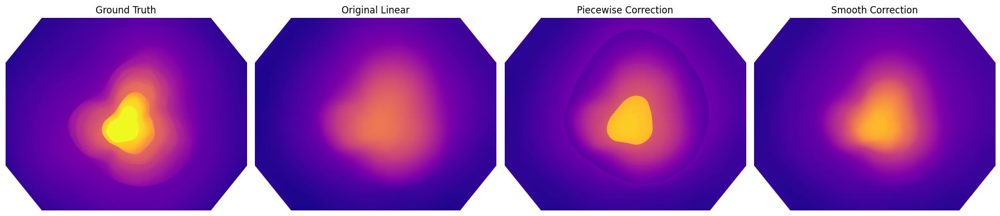

In [49]:
import numpy as np
import matplotlib.pyplot as plt

# Midpoints of the trained depth intervals
bin_centers = np.array([10, 30, 50, 70], dtype=np.float32)

# Corrections learned from 45 training frames
bin_corrections = np.array(corrections[:4], dtype=np.float32)

# Interpolate corrections smoothly
smooth_correction = np.interp(
    linear_depth,
    bin_centers,
    bin_corrections
)

# Apply correction
smooth_depth = np.clip(
    linear_depth + smooth_correction,
    1e-3,
    100.0
)

# Calculate MAE
smooth_mae = np.mean(
    np.abs(gt_mm[valid] - smooth_depth[valid])
)

print("Original MAE:", np.mean(
    np.abs(gt_mm[valid] - linear_depth[valid])
))

print("Piecewise corrected MAE:", np.mean(
    np.abs(gt_mm[valid] - corrected_depth[valid])
))

print("Smooth corrected MAE:", smooth_mae)

# Visualize
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

maps = [
    gt_mm,
    linear_depth,
    corrected_depth,
    smooth_depth
]

titles = [
    "Ground Truth",
    "Original Linear",
    "Piecewise Correction",
    "Smooth Correction"
]

for ax, depth_map, title in zip(axes, maps, titles):
    ax.imshow(
        np.where(valid, depth_map, np.nan),
        cmap="plasma",
        vmin=0,
        vmax=100
    )
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [50]:
import os
import cv2
import numpy as np

methods = ["Linear", "Piecewise", "Smooth"]

results_val = {
    name: {"absrel": [], "sqerr": [], "delta": [], "mae": []}
    for name in methods
}

bin_centers = np.array([10, 30, 50, 70], dtype=np.float32)
bin_corrections = np.array(corrections[:4], dtype=np.float32)

for filename in val_files:

    pred = np.load(os.path.join(output_folder, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0
    valid = gt_raw > 0

    # Original linear calibration
    linear = np.clip(
        -train_scale * pred + train_offset,
        1e-3, 100.0
    )

    # Piecewise correction
    piecewise = linear.copy()

    for i in range(len(bins) - 1):
        low, high = bins[i], bins[i + 1]

        if high == 100:
            mask = (linear >= low) & (linear <= high)
        else:
            mask = (linear >= low) & (linear < high)

        piecewise[mask] += corrections[i]

    piecewise = np.clip(piecewise, 1e-3, 100.0)

    # Smooth correction
    smooth = np.clip(
        linear + np.interp(
            linear, bin_centers, bin_corrections
        ),
        1e-3, 100.0
    )

    gt = gt_mm[valid]

    for name, depth_map in [
        ("Linear", linear),
        ("Piecewise", piecewise),
        ("Smooth", smooth)
    ]:
        prediction = depth_map[valid]

        results_val[name]["mae"].append(
            np.mean(np.abs(gt - prediction))
        )

        results_val[name]["absrel"].append(
            np.mean(np.abs(gt - prediction) / gt)
        )

        results_val[name]["sqerr"].append(
            np.mean((gt - prediction) ** 2)
        )

        ratio = np.maximum(
            gt / prediction,
            prediction / gt
        )

        results_val[name]["delta"].append(
            np.mean(ratio < 1.25)
        )

print("VALIDATION RESULTS — ALL 16 FRAMES")
print("-" * 75)

for name, values in results_val.items():

    mae = np.mean(values["mae"])
    absrel = np.mean(values["absrel"])
    rmse = np.sqrt(np.mean(values["sqerr"]))
    delta = np.mean(values["delta"])

    print(
        f"{name:<12} "
        f"MAE={mae:.4f} mm | "
        f"AbsRel={absrel:.4f} | "
        f"RMSE={rmse:.4f} mm | "
        f"Delta={delta:.4f}"
    )

VALIDATION RESULTS — ALL 16 FRAMES
---------------------------------------------------------------------------
Linear       MAE=5.9373 mm | AbsRel=0.3128 | RMSE=8.4090 mm | Delta=0.4395
Piecewise    MAE=4.6796 mm | AbsRel=0.2686 | RMSE=6.1306 mm | Delta=0.5137
Smooth       MAE=4.4756 mm | AbsRel=0.2507 | RMSE=5.9381 mm | Delta=0.5343


In [51]:
import os
import json
import numpy as np
import pandas as pd

save_folder = (
    "/content/drive/MyDrive/"
    "BN5211_Depth_Project/DepthAnythingV2"
)

os.makedirs(save_folder, exist_ok=True)

# Save the correction model
improvement_parameters = {
    "method": "Smooth Depth-Dependent Bias Correction",
    "training_frames": "0000-0044",
    "validation_frames": "0045-0060",
    "train_scale": float(train_scale),
    "train_offset": float(train_offset),
    "bin_centers_mm": [10, 30, 50, 70],
    "bin_corrections_mm": [
        float(v) for v in corrections[:4]
    ],
    "valid_mask": "gt_raw > 0",
    "interpolation": "numpy.interp"
}

with open(
    f"{save_folder}/smooth_correction_parameters.json", "w"
) as f:
    json.dump(improvement_parameters, f, indent=4)

# Save validation results
rows = []

for name, values in results_val.items():
    rows.append({
        "Method": name,
        "MAE_mm": float(np.mean(values["mae"])),
        "AbsRel": float(np.mean(values["absrel"])),
        "RMSE_mm": float(np.sqrt(np.mean(values["sqerr"]))),
        "Delta_1.25": float(np.mean(values["delta"]))
    })

df = pd.DataFrame(rows)

df.to_csv(
    f"{save_folder}/validation_comparison.csv",
    index=False
)

print("Improvement parameters saved successfully!")
print("Validation results saved successfully!")
print(df.to_string(index=False))

Improvement parameters saved successfully!
Validation results saved successfully!
   Method   MAE_mm   AbsRel  RMSE_mm  Delta_1.25
   Linear 5.937329 0.312809 8.409050    0.439460
Piecewise 4.679622 0.268627 6.130557    0.513721
   Smooth 4.475567 0.250692 5.938050    0.534280


In [52]:
import os
import cv2
import numpy as np

# Fixed depth intervals selected during validation
bins = np.array([0, 20, 40, 60, 80, 100])
bin_centers = np.array([10, 30, 50, 70])

error_sums = np.zeros(5, dtype=np.float64)
pixel_counts = np.zeros(5, dtype=np.int64)

for filename in prediction_files:

    # Load Depth Anything V2 prediction
    pred = np.load(
        os.path.join(output_folder, filename)
    )

    # Load ground-truth depth
    gt_filename = filename.replace(
        "_pred.npy", "_depth.tiff"
    )

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Use final 61-frame linear calibration
    pred_mm = np.clip(
        -scale * pred + offset,
        1e-3, 100.0
    )

    valid = gt_raw > 0

    # Positive error = depth underestimation
    signed_error = gt_mm - pred_mm

    for i in range(len(bins) - 1):

        low = bins[i]
        high = bins[i + 1]

        if high == 100:
            mask = valid & (pred_mm >= low) & (pred_mm <= high)
        else:
            mask = valid & (pred_mm >= low) & (pred_mm < high)

        error_sums[i] += np.sum(
            signed_error[mask],
            dtype=np.float64
        )

        pixel_counts[i] += np.count_nonzero(mask)

final_corrections = np.divide(
    error_sums,
    pixel_counts,
    out=np.zeros(5, dtype=np.float64),
    where=pixel_counts > 0
)

print("FINAL SMOOTH CORRECTION PARAMETERS")
print("-" * 55)

for i in range(5):
    print(
        f"{bins[i]}-{bins[i+1]} mm: "
        f"Correction = {final_corrections[i]:.3f} mm, "
        f"Pixels = {pixel_counts[i]}"
    )

print("\nFinal correction model ready!")

FINAL SMOOTH CORRECTION PARAMETERS
-------------------------------------------------------
0-20 mm: Correction = 1.852 mm, Pixels = 42761235
20-40 mm: Correction = -5.170 mm, Pixels = 21284495
40-60 mm: Correction = -5.013 mm, Pixels = 13919401
60-80 mm: Correction = 20.718 mm, Pixels = 4747880
80-100 mm: Correction = 0.000 mm, Pixels = 0

Final correction model ready!


In [53]:
import os
import cv2
import numpy as np

methods = [
    "Constant Median",
    "Depth Anything V2",
    "Improved Depth Anything V2"
]

test_results = {
    name: {"mae": [], "absrel": [], "sqerr": [], "delta": []}
    for name in methods
}

# Fixed correction parameters learned from development data
centers = np.array([10, 30, 50, 70])
correction_values = final_corrections[:4]

for filename in sorted(os.listdir(test_output)):

    if not filename.endswith("_pred.npy"):
        continue

    # Load saved AI prediction
    pred = np.load(
        os.path.join(test_output, filename)
    )

    # Load ground-truth depth
    gt_filename = filename.replace(
        "_pred.npy", "_depth.tiff"
    )

    gt_raw = cv2.imread(
        os.path.join(test_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Missing: {gt_filename}")

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Evaluation mask
    valid = gt_raw > 0
    gt = gt_mm[valid]

    # Model 1: Constant median baseline
    baseline = np.full_like(gt_mm, median_depth)

    # Model 2: Original linear calibration
    linear = np.clip(
        -scale * pred + offset,
        1e-3, 100.0
    )

    # Model 3: Smooth depth-dependent correction
    correction = np.interp(
        linear, centers, correction_values
    )

    improved = np.clip(
        linear + correction,
        1e-3, 100.0
    )

    for name, depth_map in [
        ("Constant Median", baseline),
        ("Depth Anything V2", linear),
        ("Improved Depth Anything V2", improved)
    ]:

        prediction = depth_map[valid]

        test_results[name]["mae"].append(
            np.mean(np.abs(gt - prediction))
        )

        test_results[name]["absrel"].append(
            np.mean(np.abs(gt - prediction) / gt)
        )

        test_results[name]["sqerr"].append(
            np.mean((gt - prediction) ** 2)
        )

        ratio = np.maximum(
            gt / prediction,
            prediction / gt
        )

        test_results[name]["delta"].append(
            np.mean(ratio < 1.25)
        )

print("FINAL TEST RESULTS — 103 FRAMES")
print("-" * 85)

for name, values in test_results.items():

    mae = np.mean(values["mae"])
    absrel = np.mean(values["absrel"])
    rmse = np.sqrt(np.mean(values["sqerr"]))
    delta = np.mean(values["delta"])

    print(
        f"{name:<28} "
        f"MAE={mae:.4f} | "
        f"AbsRel={absrel:.4f} | "
        f"RMSE={rmse:.4f} mm | "
        f"Delta={delta:.4f}"
    )

FINAL TEST RESULTS — 103 FRAMES
-------------------------------------------------------------------------------------
Constant Median              MAE=12.9760 | AbsRel=0.5655 | RMSE=21.2086 mm | Delta=0.2704
Depth Anything V2            MAE=6.4007 | AbsRel=0.3700 | RMSE=8.7136 mm | Delta=0.4162
Improved Depth Anything V2   MAE=4.6530 | AbsRel=0.2825 | RMSE=5.8733 mm | Delta=0.5444


In [54]:
import os
import json
import numpy as np
import pandas as pd

save_folder = (
    "/content/drive/MyDrive/"
    "BN5211_Depth_Project/DepthAnythingV2"
)

os.makedirs(save_folder, exist_ok=True)

# Save final correction parameters
final_parameters = {
    "model": "Depth Anything V2 Small",
    "improvement": "Smooth Depth-Dependent Bias Correction",
    "development_dataset": "trans_t1_a",
    "test_dataset": "trans_t2_b",
    "scale": float(scale),
    "offset": float(offset),
    "median_depth_mm": float(median_depth),
    "bin_centers_mm": [10, 30, 50, 70],
    "correction_values_mm": [
        float(v) for v in final_corrections[:4]
    ],
    "evaluation_mask": "gt_raw > 0",
    "depth_range_mm": [0, 100],
    "input_size": 518
}

with open(
    f"{save_folder}/final_model_parameters.json", "w"
) as f:
    json.dump(final_parameters, f, indent=4)

# Save final comparison
rows = []

for name, values in test_results.items():
    rows.append({
        "Method": name,
        "MAE_mm": float(np.mean(values["mae"])),
        "AbsRel": float(np.mean(values["absrel"])),
        "RMSE_mm": float(np.sqrt(np.mean(values["sqerr"]))),
        "Delta_1.25": float(np.mean(values["delta"]))
    })

df_final = pd.DataFrame(rows)

df_final.to_csv(
    f"{save_folder}/final_test_comparison.csv",
    index=False
)

print("Final results saved successfully!")
print("Final correction parameters saved successfully!")
print(df_final.to_string(index=False))

Final results saved successfully!
Final correction parameters saved successfully!
                    Method    MAE_mm   AbsRel   RMSE_mm  Delta_1.25
           Constant Median 12.975951 0.565481 21.208551    0.270393
         Depth Anything V2  6.400699 0.370023  8.713642    0.416236
Improved Depth Anything V2  4.653020 0.282546  5.873254    0.544395


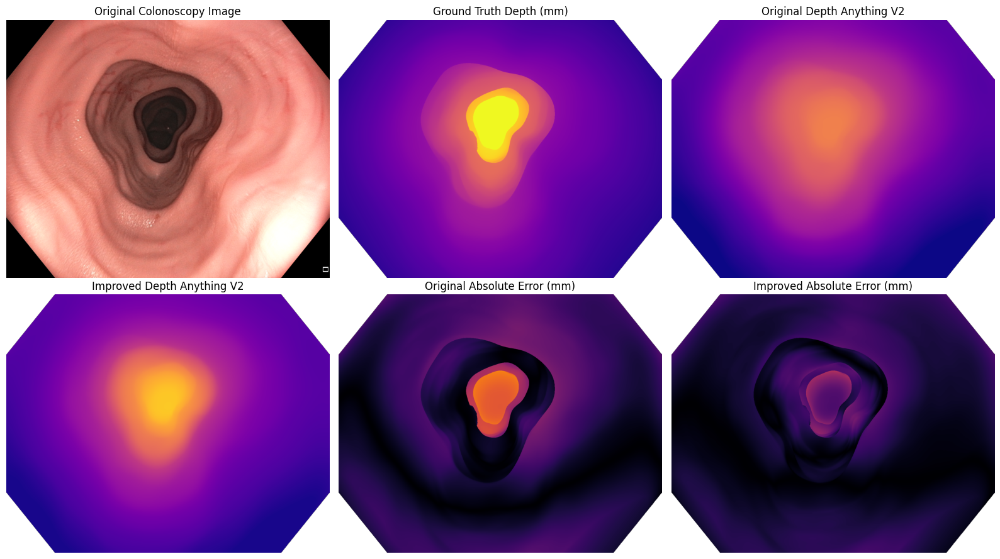

Original MAE: 7.4650087
Improved MAE: 5.1743804815394085
Figure saved to: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/final_depth_comparison.png


In [55]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Choose one test frame for visualization
frame = "0001"

# Load C3VD test image
rgb_bgr = cv2.imread(
    f"{test_folder}/{frame}_color.png"
)
rgb = cv2.cvtColor(rgb_bgr, cv2.COLOR_BGR2RGB)

# Load ground truth
gt_raw = cv2.imread(
    f"{test_folder}/{frame}_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0
valid = gt_raw > 0

# Load pretrained model prediction
pred = np.load(
    f"{test_output}/{frame}_pred.npy"
)

# Original calibrated prediction
linear = np.clip(
    -scale * pred + offset,
    1e-3, 100.0
)

# Improved prediction using final correction
correction = np.interp(
    linear,
    [10, 30, 50, 70],
    final_corrections[:4]
)

improved = np.clip(
    linear + correction,
    1e-3, 100.0
)

# Mask invalid pixels
gt_display = np.where(valid, gt_mm, np.nan)
linear_display = np.where(valid, linear, np.nan)
improved_display = np.where(valid, improved, np.nan)

# Absolute error maps
linear_error = np.where(
    valid, np.abs(gt_mm - linear), np.nan
)

improved_error = np.where(
    valid, np.abs(gt_mm - improved), np.nan
)

# Create figure
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes[0, 0].imshow(rgb)
axes[0, 0].set_title("Original Colonoscopy Image")

axes[0, 1].imshow(
    gt_display, cmap="plasma", vmin=0, vmax=100
)
axes[0, 1].set_title("Ground Truth Depth (mm)")

axes[0, 2].imshow(
    linear_display, cmap="plasma", vmin=0, vmax=100
)
axes[0, 2].set_title("Original Depth Anything V2")

axes[1, 0].imshow(
    improved_display, cmap="plasma", vmin=0, vmax=100
)
axes[1, 0].set_title("Improved Depth Anything V2")

axes[1, 1].imshow(
    linear_error, cmap="inferno", vmin=0, vmax=50
)
axes[1, 1].set_title("Original Absolute Error (mm)")

axes[1, 2].imshow(
    improved_error, cmap="inferno", vmin=0, vmax=50
)
axes[1, 2].set_title("Improved Absolute Error (mm)")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()

# Save to Google Drive
save_path = os.path.join(
    save_folder,
    "final_depth_comparison.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Print errors for this frame
print(
    "Original MAE:",
    np.mean(np.abs(gt_mm[valid] - linear[valid]))
)

print(
    "Improved MAE:",
    np.mean(np.abs(gt_mm[valid] - improved[valid]))
)

print("Figure saved to:", save_path)

In [56]:
import numpy as np
import cv2

# Load one test frame
frame = "0001"

gt_raw = cv2.imread(
    f"{test_folder}/{frame}_depth.tiff",
    cv2.IMREAD_UNCHANGED
)

gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

pred = np.load(
    f"{test_output}/{frame}_pred.npy"
)

# Apply original calibration
linear = np.clip(
    -scale * pred + offset,
    1e-3, 100.0
)

# Apply smooth correction
improved = np.clip(
    linear + np.interp(
        linear,
        [10, 30, 50, 70],
        final_corrections[:4]
    ),
    1e-3, 100.0
)

# Evaluation mask
valid = gt_raw > 0

gt = gt_mm[valid].astype(np.float64)
prediction = improved[valid].astype(np.float64)

# Calculate metrics
absrel = np.mean(
    np.abs(gt - prediction) / gt
)

rmse = np.sqrt(
    np.mean((gt - prediction) ** 2)
)

delta = np.mean(
    np.maximum(
        gt / prediction,
        prediction / gt
    ) < 1.25
)

print("EVALUATION VERIFICATION")
print("-----------------------")
print("Valid pixels:", valid.sum())
print("AbsRel:", round(absrel, 6))
print("RMSE (mm):", round(rmse, 6))
print("Delta < 1.25:", round(delta, 6))

print("\nDepth mask:")
print("Zero-depth pixels excluded:", np.sum(gt_raw == 0))
print("100 mm pixels included:", np.sum(gt_raw == 65535))

EVALUATION VERIFICATION
-----------------------
Valid pixels: 1355951
AbsRel: 0.299395
RMSE (mm): 6.18745
Delta < 1.25: 0.51348

Depth mask:
Zero-depth pixels excluded: 102049
100 mm pixels included: 29867


In [57]:
import os
import cv2
import numpy as np

total_pixels = 0
total_absrel = 0.0
total_squared_error = 0.0
total_delta_correct = 0

for filename in sorted(os.listdir(test_output)):

    if not filename.endswith("_pred.npy"):
        continue

    pred = np.load(os.path.join(test_output, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(test_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    valid = gt_raw > 0

    linear = np.clip(
        -scale * pred + offset,
        1e-3, 100.0
    )

    improved = np.clip(
        linear + np.interp(
            linear,
            [10, 30, 50, 70],
            final_corrections[:4]
        ),
        1e-3, 100.0
    )

    gt = gt_mm[valid].astype(np.float64)
    prediction = improved[valid].astype(np.float64)

    total_pixels += gt.size

    total_absrel += np.sum(
        np.abs(gt - prediction) / gt
    )

    total_squared_error += np.sum(
        (gt - prediction) ** 2
    )

    total_delta_correct += np.count_nonzero(
        np.maximum(
            gt / prediction,
            prediction / gt
        ) < 1.25
    )

global_absrel = total_absrel / total_pixels
global_rmse = np.sqrt(total_squared_error / total_pixels)
global_delta = total_delta_correct / total_pixels

print("GLOBAL PIXEL-WEIGHTED TEST RESULTS")
print("----------------------------------")
print("Total valid pixels:", total_pixels)
print("AbsRel:", round(global_absrel, 6))
print("RMSE (mm):", round(global_rmse, 6))
print("Delta < 1.25:", round(global_delta, 6))

GLOBAL PIXEL-WEIGHTED TEST RESULTS
----------------------------------
Total valid pixels: 139662953
AbsRel: 0.282546
RMSE (mm): 5.873254
Delta < 1.25: 0.544395


In [58]:
import os
import cv2
import numpy as np

frame_errors = []

for filename in sorted(os.listdir(test_output)):
    if not filename.endswith("_pred.npy"):
        continue

    frame = filename.replace("_pred.npy", "")

    pred = np.load(os.path.join(test_output, filename))

    gt_raw = cv2.imread(
        f"{test_folder}/{frame}_depth.tiff",
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0
    valid = gt_raw > 0

    linear = np.clip(
        -scale * pred + offset,
        1e-3, 100.0
    )

    improved = np.clip(
        linear + np.interp(
            linear,
            [10, 30, 50, 70],
            final_corrections[:4]
        ),
        1e-3, 100.0
    )

    rmse = np.sqrt(
        np.mean(
            (gt_mm[valid] - improved[valid]) ** 2
        )
    )

    frame_errors.append((frame, float(rmse)))

# Sort from highest to lowest error
frame_errors.sort(key=lambda x: x[1], reverse=True)

print("TOP 3 FAILURE CASES")
print("--------------------")

for frame, rmse in frame_errors[:3]:
    print(f"Frame {frame}: RMSE = {rmse:.4f} mm")

print("\nTOP 3 BEST CASES")
print("----------------")

for frame, rmse in frame_errors[-3:]:
    print(f"Frame {frame}: RMSE = {rmse:.4f} mm")

TOP 3 FAILURE CASES
--------------------
Frame 0072: RMSE = 7.0227 mm
Frame 0076: RMSE = 6.9582 mm
Frame 0078: RMSE = 6.8542 mm

TOP 3 BEST CASES
----------------
Frame 0091: RMSE = 4.8379 mm
Frame 0101: RMSE = 4.7737 mm
Frame 0102: RMSE = 4.6731 mm


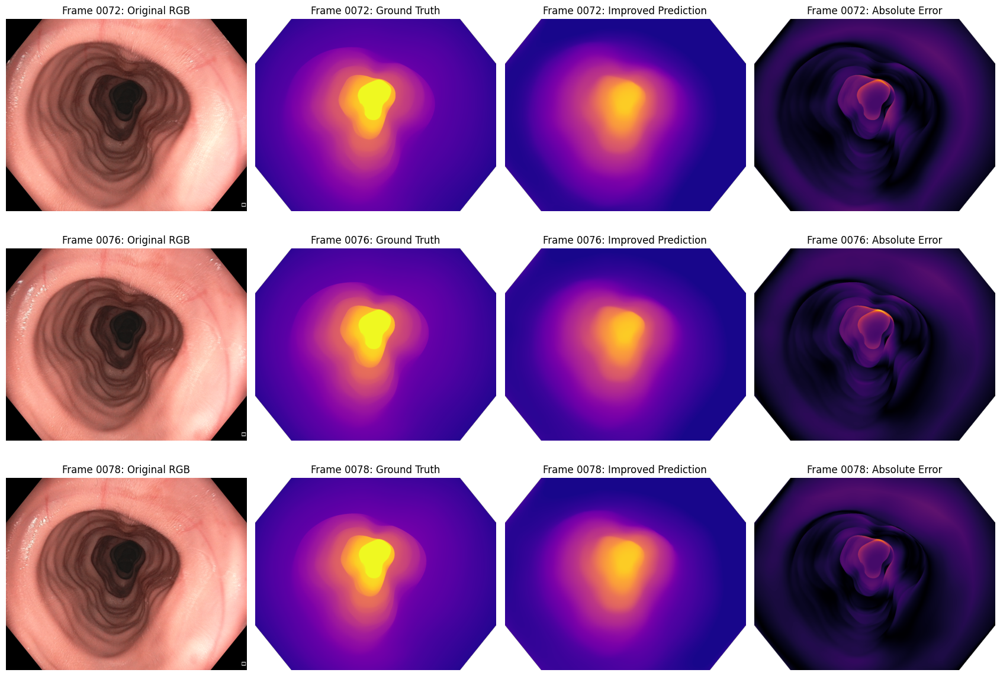

Failure-case figure saved to: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/failure_cases.png


In [59]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

failure_frames = ["0072", "0076", "0078"]

fig, axes = plt.subplots(3, 4, figsize=(17, 12))

for row, frame in enumerate(failure_frames):

    rgb = cv2.cvtColor(
        cv2.imread(f"{test_folder}/{frame}_color.png"),
        cv2.COLOR_BGR2RGB
    )

    gt_raw = cv2.imread(
        f"{test_folder}/{frame}_depth.tiff",
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0
    valid = gt_raw > 0

    pred = np.load(f"{test_output}/{frame}_pred.npy")

    linear = np.clip(
        -scale * pred + offset,
        1e-3, 100.0
    )

    improved = np.clip(
        linear + np.interp(
            linear,
            [10, 30, 50, 70],
            final_corrections[:4]
        ),
        1e-3, 100.0
    )

    error = np.abs(gt_mm - improved)

    images = [
        rgb,
        np.where(valid, gt_mm, np.nan),
        np.where(valid, improved, np.nan),
        np.where(valid, error, np.nan)
    ]

    titles = [
        "Original RGB",
        "Ground Truth",
        "Improved Prediction",
        "Absolute Error"
    ]

    for col in range(4):
        ax = axes[row, col]

        if col == 0:
            ax.imshow(images[col])
        else:
            ax.imshow(
                images[col],
                cmap="inferno" if col == 3 else "plasma",
                vmin=0,
                vmax=50 if col == 3 else 100
            )

        ax.set_title(f"Frame {frame}: {titles[col]}")
        ax.axis("off")

plt.tight_layout()

save_path = f"{save_folder}/failure_cases.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Failure-case figure saved to:", save_path)

In [60]:
import torch
from google.colab import drive

drive.mount('/content/drive')

print("GPU available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU available: True
GPU: Tesla T4


In [61]:
# Dataset already prepared from your extracted Google Drive folders.
# Do not try to open missing .zip files.
from pathlib import Path
for name in ["trans_t1_a", "trans_t2_b"]:
    folder = Path("/content/C3VD") / name / name
    assert folder.is_dir() and list(folder.glob("*_color.png")), f"Missing prepared data: {folder}"
    print(name, "ready:", len(list(folder.glob("*_color.png"))), "RGB frames")


trans_t1_a ready: 61 RGB frames
trans_t2_b ready: 103 RGB frames


In [62]:
dev_folder = "/content/C3VD/trans_t1_a/trans_t1_a"
test_folder = "/content/C3VD/trans_t2_b/trans_t2_b"

print("Development images:", len([
    f for f in os.listdir(dev_folder)
    if f.endswith("_color.png")
]))

print("Test images:", len([
    f for f in os.listdir(test_folder)
    if f.endswith("_color.png")
]))

Development images: 61
Test images: 103


In [63]:
%cd /content

!git clone https://github.com/DepthAnything/Depth-Anything-V2.git

%cd /content/Depth-Anything-V2

/content
fatal: destination path 'Depth-Anything-V2' already exists and is not an empty directory.
/content/Depth-Anything-V2


In [64]:
!pip install -q -r requirements.txt

In [65]:
import os
import torch

print("Current directory:", os.getcwd())
print("Model code available:",
      os.path.exists("depth_anything_v2/dpt.py"))

print("GPU:", torch.cuda.get_device_name(0))

Current directory: /content/Depth-Anything-V2
Model code available: True
GPU: Tesla T4


In [66]:
%cd /content/Depth-Anything-V2

# Create folder for model weights
!mkdir -p checkpoints

# Download Depth Anything V2 Large pretrained weights
!wget -q --show-progress \
https://huggingface.co/depth-anything/Depth-Anything-V2-Large/resolve/main/depth_anything_v2_vitl.pth \
-O checkpoints/depth_anything_v2_vitl.pth

/content/Depth-Anything-V2
checkpoints/depth_a 100%[===================>]   1.25G   120MB/s    in 17s     


In [67]:
import os

model_path = "checkpoints/depth_anything_v2_vitl.pth"

print("Weights downloaded:", os.path.exists(model_path))
print("File size (GB):", round(os.path.getsize(model_path) / 1e9, 2))

Weights downloaded: True
File size (GB): 1.34


In [68]:
import torch
from depth_anything_v2.dpt import DepthAnythingV2

# Configure Depth Anything V2 Large
model_large = DepthAnythingV2(
    encoder='vitl',
    features=256,
    out_channels=[256, 512, 1024, 1024]
)

# Load pretrained weights
model_large.load_state_dict(
    torch.load(
        'checkpoints/depth_anything_v2_vitl.pth',
        map_location='cpu',
        weights_only=True
    )
)

# Move model to GPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'

model_large = model_large.to(device).eval()

print("Model loaded successfully!")
print("Model: Depth Anything V2 Large")
print("Running on:", device)
print("GPU:", torch.cuda.get_device_name(0))

Model loaded successfully!
Model: Depth Anything V2 Large
Running on: cuda
GPU: Tesla T4


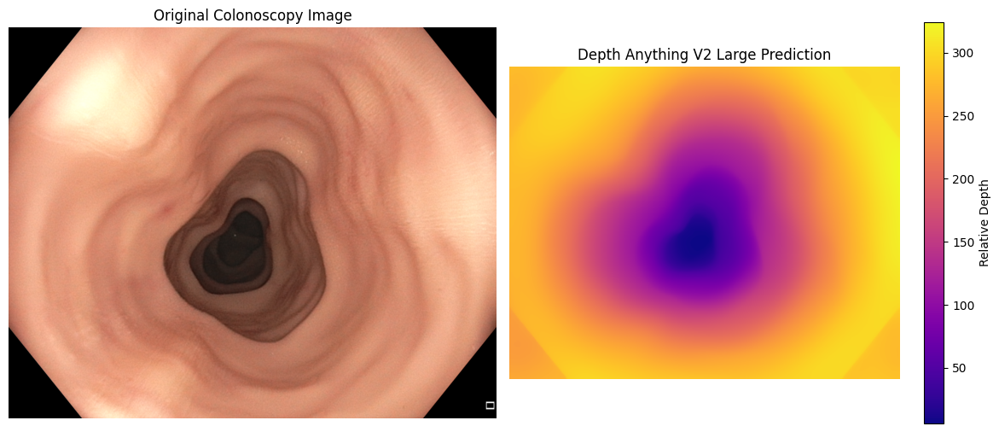

Prediction shape: (1080, 1350)
Minimum prediction: 5.9551625
Maximum prediction: 324.145


In [69]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

# Load first C3VD development image
image_path = "/content/C3VD/trans_t1_a/trans_t1_a/0001_color.png"

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(image_path)

# Run Depth Anything V2 Large
with torch.inference_mode():
    predicted_large = model_large.infer_image(
        image,
        input_size=518
    )

# Display original image and prediction
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb)
plt.title("Original Colonoscopy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(predicted_large, cmap="plasma")
plt.title("Depth Anything V2 Large Prediction")
plt.colorbar(label="Relative Depth")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Prediction shape:", predicted_large.shape)
print("Minimum prediction:", predicted_large.min())
print("Maximum prediction:", predicted_large.max())

In [70]:
import os
import cv2
import numpy as np
import torch

dev_folder = "/content/C3VD/trans_t1_a/trans_t1_a"

large_output = "/content/C3VD/large_dev_predictions"
os.makedirs(large_output, exist_ok=True)

image_files = sorted([
    f for f in os.listdir(dev_folder)
    if f.endswith("_color.png")
])

print("Total development images:", len(image_files))

model_large.eval()

for i, filename in enumerate(image_files):

    image = cv2.imread(
        os.path.join(dev_folder, filename)
    )

    if image is None:
        raise RuntimeError(f"Cannot load {filename}")

    with torch.inference_mode():
        prediction = model_large.infer_image(
            image,
            input_size=518
        )

    output_name = filename.replace(
        "_color.png", "_pred.npy"
    )

    np.save(
        os.path.join(large_output, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(image_files):
        print(f"Processed {i + 1}/{len(image_files)}")

print("All Large model development predictions saved!")

Total development images: 61
Processed 10/61
Processed 20/61
Processed 30/61
Processed 40/61
Processed 50/61
Processed 60/61
Processed 61/61
All Large model development predictions saved!


In [71]:
import os
import cv2
import numpy as np
from sklearn.linear_model import LinearRegression

X_large = []
y_large = []

prediction_files_large = sorted([
    f for f in os.listdir(large_output)
    if f.endswith("_pred.npy")
])

for filename in prediction_files_large:

    # Load Large model prediction
    pred = np.load(
        os.path.join(large_output, filename)
    )

    # Load corresponding ground-truth depth
    gt_filename = filename.replace(
        "_pred.npy", "_depth.tiff"
    )

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {gt_filename}")

    # Convert ground truth to millimeters
    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Use the same evaluation mask as Small
    valid = gt_raw > 0

    # Negative prediction reverses the depth direction
    X_large.append((-pred[valid]).reshape(-1, 1))
    y_large.append(gt_mm[valid])

X_large = np.concatenate(X_large)
y_large = np.concatenate(y_large)

# Fit linear calibration
large_calibrator = LinearRegression()
large_calibrator.fit(X_large, y_large)

large_scale = float(large_calibrator.coef_[0])
large_offset = float(large_calibrator.intercept_)

print("LARGE MODEL CALIBRATION")
print("-----------------------")
print("Development frames:", len(prediction_files_large))
print("Valid pixels:", len(y_large))
print("Scale:", large_scale)
print("Offset:", large_offset)
print("Calibration completed!")

LARGE MODEL CALIBRATION
-----------------------
Development frames: 61
Valid pixels: 82713011
Scale: 0.222745880484581
Offset: 75.89997863769531
Calibration completed!


In [72]:
import os
import cv2
import numpy as np

absrel_values = []
squared_errors = []
delta_values = []

for filename in prediction_files_large:

    pred = np.load(os.path.join(large_output, filename))

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Convert relative prediction into millimeters
    pred_mm = np.clip(
        -large_scale * pred + large_offset,
        1e-3,
        100.0
    )

    valid = gt_raw > 0

    gt = gt_mm[valid]
    prediction = pred_mm[valid]

    # AbsRel
    absrel_values.append(
        np.mean(np.abs(gt - prediction) / gt)
    )

    # Squared error for RMSE
    squared_errors.append(
        np.mean((gt - prediction) ** 2)
    )

    # Delta < 1.25
    ratio = np.maximum(
        gt / prediction,
        prediction / gt
    )

    delta_values.append(
        np.mean(ratio < 1.25)
    )

print("LARGE MODEL — DEVELOPMENT RESULTS")
print("----------------------------------")
print("AbsRel:", round(np.mean(absrel_values), 4))
print("RMSE (mm):", round(np.sqrt(np.mean(squared_errors)), 4))
print("Delta < 1.25:", round(np.mean(delta_values), 4))

LARGE MODEL — DEVELOPMENT RESULTS
----------------------------------
AbsRel: 0.33
RMSE (mm): 8.3288
Delta < 1.25: 0.4827


In [73]:
import os
import cv2
import numpy as np
import torch

test_folder = "/content/C3VD/trans_t2_b/trans_t2_b"
large_test_output = "/content/C3VD/large_test_predictions"

os.makedirs(large_test_output, exist_ok=True)

test_files = sorted([
    f for f in os.listdir(test_folder)
    if f.endswith("_color.png")
])

print("Total test images:", len(test_files))

model_large.eval()

for i, filename in enumerate(test_files):

    image = cv2.imread(
        os.path.join(test_folder, filename)
    )

    if image is None:
        raise RuntimeError(f"Cannot load {filename}")

    with torch.inference_mode():
        prediction = model_large.infer_image(
            image,
            input_size=518
        )

    output_name = filename.replace(
        "_color.png", "_pred.npy"
    )

    np.save(
        os.path.join(large_test_output, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(test_files):
        print(f"Processed {i + 1}/{len(test_files)}")

print("All Large model test predictions saved!")

Total test images: 103
Processed 10/103
Processed 20/103
Processed 30/103
Processed 40/103
Processed 50/103
Processed 60/103
Processed 70/103
Processed 80/103
Processed 90/103
Processed 100/103
Processed 103/103
All Large model test predictions saved!


In [74]:
import os
import cv2
import numpy as np

mae_values = []
absrel_values = []
squared_errors = []
delta_values = []

prediction_files = sorted([
    f for f in os.listdir(large_test_output)
    if f.endswith("_pred.npy")
])

for filename in prediction_files:

    # Load Large model prediction
    pred = np.load(
        os.path.join(large_test_output, filename)
    )

    # Load ground-truth depth
    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(test_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {gt_filename}")

    # Convert ground truth into millimeters
    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Apply development-set calibration
    pred_mm = np.clip(
        -large_scale * pred + large_offset,
        1e-3,
        100.0
    )

    # Same evaluation mask as Small model
    valid = gt_raw > 0

    gt = gt_mm[valid]
    prediction = pred_mm[valid]

    # MAE
    mae_values.append(
        np.mean(np.abs(gt - prediction))
    )

    # AbsRel
    absrel_values.append(
        np.mean(np.abs(gt - prediction) / gt)
    )

    # RMSE
    squared_errors.append(
        np.mean((gt - prediction) ** 2)
    )

    # Delta < 1.25
    ratio = np.maximum(
        gt / prediction,
        prediction / gt
    )

    delta_values.append(
        np.mean(ratio < 1.25)
    )

print("DEPTH ANYTHING V2 LARGE — TEST RESULTS")
print("---------------------------------------")
print("Test frames:", len(prediction_files))
print("MAE (mm):", round(np.mean(mae_values), 4))
print("AbsRel:", round(np.mean(absrel_values), 4))
print("RMSE (mm):", round(np.sqrt(np.mean(squared_errors)), 4))
print("Delta < 1.25:", round(np.mean(delta_values), 4))

DEPTH ANYTHING V2 LARGE — TEST RESULTS
---------------------------------------
Test frames: 103
MAE (mm): 5.0184
AbsRel: 0.2838
RMSE (mm): 7.2077
Delta < 1.25: 0.5531


In [75]:
import os
import json
import shutil

save_large = (
    "/content/drive/MyDrive/"
    "BN5211_Depth_Project/DepthAnythingV2/Large"
)

os.makedirs(save_large, exist_ok=True)

# Save development and test predictions
for source, folder_name in [
    (large_output, "dev_predictions"),
    (large_test_output, "test_predictions")
]:
    shutil.copytree(
        source,
        os.path.join(save_large, folder_name),
        dirs_exist_ok=True
    )

# Save calibration and evaluation results
large_results = {
    "model": "Depth Anything V2 Large",
    "encoder": "vitl",
    "development_sequence": "trans_t1_a",
    "test_sequence": "trans_t2_b",
    "scale": float(large_scale),
    "offset": float(large_offset),
    "MAE_mm": float(np.mean(mae_values)),
    "AbsRel": float(np.mean(absrel_values)),
    "RMSE_mm": float(np.sqrt(np.mean(squared_errors))),
    "Delta_1.25": float(np.mean(delta_values)),
    "valid_mask": "gt_raw > 0",
    "input_size": 518
}

with open(
    os.path.join(save_large, "large_results.json"), "w"
) as f:
    json.dump(large_results, f, indent=4)

print("Large model results saved successfully!")
print("Location:", save_large)

Large model results saved successfully!
Location: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/Large


In [76]:
%cd /content/Depth-Anything-V2

# Create a separate folder for metric-depth weights
!mkdir -p checkpoints_metric

# Download Large Indoor pretrained weights
!wget -q --show-progress \
https://huggingface.co/depth-anything/Depth-Anything-V2-Metric-Indoor-Large/resolve/main/depth_anything_v2_metric_hypersim_vitl.pth \
-O checkpoints_metric/depth_anything_v2_metric_hypersim_vitl.pth

/content/Depth-Anything-V2


In [77]:
import os

indoor_path = (
    "checkpoints_metric/"
    "depth_anything_v2_metric_hypersim_vitl.pth"
)

print("Weights downloaded:", os.path.exists(indoor_path))

if os.path.exists(indoor_path):
    print(
        "File size (GB):",
        round(os.path.getsize(indoor_path) / 1e9, 2)
    )

Weights downloaded: True
File size (GB): 0.0


In [78]:
%cd /content/Depth-Anything-V2

!pip install -q huggingface_hub

from huggingface_hub import hf_hub_download
import os

indoor_path = hf_hub_download(
    repo_id="depth-anything/Depth-Anything-V2-Metric-Hypersim-Large",
    filename="depth_anything_v2_metric_hypersim_vitl.pth",
    local_dir="/content/Depth-Anything-V2/checkpoints_metric"
)

print("Downloaded:", os.path.exists(indoor_path))
print("File size (GB):", round(os.path.getsize(indoor_path) / 1e9, 2))

/content/Depth-Anything-V2


depth_anything_v2_metric_hypersim_vitl.p(…): reconstructing file:   0%|          |  0.00B / 1.34GB            

depth_anything_v2_metric_hypersim_vitl.p(…): downloading bytes:           |  0.00B            

Downloaded: True
File size (GB): 1.34


In [79]:
import sys
import torch

# Remove previously imported standard model modules
for name in list(sys.modules):
    if name == "depth_anything_v2" or name.startswith("depth_anything_v2."):
        del sys.modules[name]

# Prioritize the metric-depth implementation
metric_path = "/content/Depth-Anything-V2/metric_depth"

sys.path = [p for p in sys.path if p != metric_path]
sys.path.insert(0, metric_path)

# Import metric-depth architecture
from depth_anything_v2.dpt import DepthAnythingV2 as MetricDepthAnythingV2

# Initialize Large Indoor
model_indoor = MetricDepthAnythingV2(
    encoder="vitl",
    features=256,
    out_channels=[256, 512, 1024, 1024],
    max_depth=20
)

# Load pretrained weights
model_indoor.load_state_dict(
    torch.load(
        indoor_path,
        map_location="cpu",
        weights_only=True
    )
)

model_indoor = model_indoor.to("cuda").eval()

print("Large Indoor model loaded successfully!")
print("Running on:", next(model_indoor.parameters()).device)

Large Indoor model loaded successfully!
Running on: cuda:0


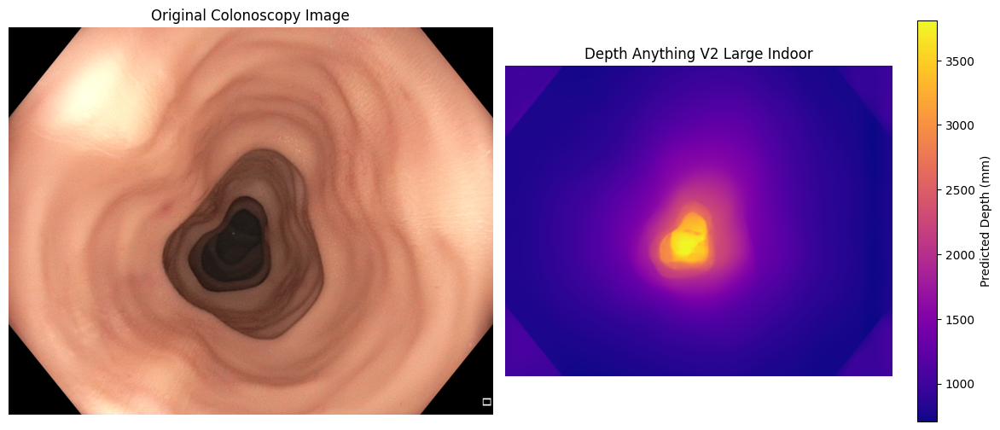

Prediction shape: (1080, 1350)
Minimum depth (mm): 706.9086
Maximum depth (mm): 3808.3015


In [80]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

# Load first C3VD development image
image_path = "/content/C3VD/trans_t1_a/trans_t1_a/0001_color.png"

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(image_path)

# Generate Indoor model prediction
with torch.inference_mode():
    predicted_indoor = model_indoor.infer_image(
        image,
        input_size=518
    )

# Convert meters to millimeters
predicted_indoor_mm = predicted_indoor * 1000.0

# Display results
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb)
plt.title("Original Colonoscopy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(predicted_indoor_mm, cmap="plasma")
plt.title("Depth Anything V2 Large Indoor")
plt.colorbar(label="Predicted Depth (mm)")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Prediction shape:", predicted_indoor_mm.shape)
print("Minimum depth (mm):", predicted_indoor_mm.min())
print("Maximum depth (mm):", predicted_indoor_mm.max())

In [81]:
import os
import cv2
import numpy as np
import torch

dev_folder = "/content/C3VD/trans_t1_a/trans_t1_a"

indoor_dev_output = "/content/C3VD/indoor_dev_predictions"
os.makedirs(indoor_dev_output, exist_ok=True)

image_files = sorted([
    f for f in os.listdir(dev_folder)
    if f.endswith("_color.png")
])

print("Total development images:", len(image_files))

model_indoor.eval()

for i, filename in enumerate(image_files):

    image = cv2.imread(
        os.path.join(dev_folder, filename)
    )

    if image is None:
        raise RuntimeError(f"Cannot load {filename}")

    with torch.inference_mode():
        prediction = model_indoor.infer_image(
            image,
            input_size=518
        )

    output_name = filename.replace(
        "_color.png", "_pred.npy"
    )

    # Save raw metric predictions in meters
    np.save(
        os.path.join(indoor_dev_output, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(image_files):
        print(f"Processed {i + 1}/{len(image_files)}")

print("All Large Indoor development predictions saved!")

Total development images: 61
Processed 10/61
Processed 20/61
Processed 30/61
Processed 40/61
Processed 50/61
Processed 60/61
Processed 61/61
All Large Indoor development predictions saved!


In [82]:
import os
import cv2
import numpy as np
from sklearn.linear_model import LinearRegression

X_indoor = []
y_indoor = []

prediction_files_indoor = sorted([
    f for f in os.listdir(indoor_dev_output)
    if f.endswith("_pred.npy")
])

for filename in prediction_files_indoor:

    # Load Indoor prediction (meters)
    pred = np.load(
        os.path.join(indoor_dev_output, filename)
    )

    # Load ground-truth depth
    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {gt_filename}")

    # Convert ground truth to millimeters
    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Same mask as previous models
    valid = gt_raw > 0

    # Convert Indoor prediction to millimeters
    pred_mm = pred * 1000.0

    X_indoor.append(pred_mm[valid].reshape(-1, 1))
    y_indoor.append(gt_mm[valid])

X_indoor = np.concatenate(X_indoor)
y_indoor = np.concatenate(y_indoor)

# Fit linear regression
indoor_calibrator = LinearRegression()
indoor_calibrator.fit(X_indoor, y_indoor)

indoor_scale = float(indoor_calibrator.coef_[0])
indoor_offset = float(indoor_calibrator.intercept_)

print("LARGE INDOOR CALIBRATION")
print("------------------------")
print("Development frames:", len(prediction_files_indoor))
print("Valid pixels:", len(y_indoor))
print("Scale:", indoor_scale)
print("Offset:", indoor_offset)
print("Calibration completed!")

LARGE INDOOR CALIBRATION
------------------------
Development frames: 61
Valid pixels: 82713011
Scale: 0.031549133360385895
Offset: -13.024480819702148
Calibration completed!


In [83]:
import os
import cv2
import numpy as np

mae_indoor = []
absrel_indoor = []
sqerr_indoor = []
delta_indoor = []

for filename in prediction_files_indoor:

    pred = np.load(
        os.path.join(indoor_dev_output, filename)
    )

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Convert meters to millimeters and calibrate
    pred_mm = np.clip(
        indoor_scale * (pred * 1000.0) + indoor_offset,
        1e-3,
        100.0
    )

    valid = gt_raw > 0

    gt = gt_mm[valid]
    prediction = pred_mm[valid]

    mae_indoor.append(
        np.mean(np.abs(gt - prediction))
    )

    absrel_indoor.append(
        np.mean(np.abs(gt - prediction) / gt)
    )

    sqerr_indoor.append(
        np.mean((gt - prediction) ** 2)
    )

    ratio = np.maximum(
        gt / prediction,
        prediction / gt
    )

    delta_indoor.append(
        np.mean(ratio < 1.25)
    )

print("LARGE INDOOR — DEVELOPMENT RESULTS")
print("-----------------------------------")
print("MAE (mm):", round(np.mean(mae_indoor), 4))
print("AbsRel:", round(np.mean(absrel_indoor), 4))
print("RMSE (mm):", round(np.sqrt(np.mean(sqerr_indoor)), 4))
print("Delta < 1.25:", round(np.mean(delta_indoor), 4))

LARGE INDOOR — DEVELOPMENT RESULTS
-----------------------------------
MAE (mm): 4.5518
AbsRel: 0.3052
RMSE (mm): 5.9881
Delta < 1.25: 0.5407


In [84]:
import os
import cv2
import numpy as np
import torch

test_folder = "/content/C3VD/trans_t2_b/trans_t2_b"
indoor_test_output = "/content/C3VD/indoor_test_predictions"

os.makedirs(indoor_test_output, exist_ok=True)

test_files = sorted([
    f for f in os.listdir(test_folder)
    if f.endswith("_color.png")
])

print("Total test images:", len(test_files))

model_indoor.eval()

for i, filename in enumerate(test_files):

    image = cv2.imread(
        os.path.join(test_folder, filename)
    )

    if image is None:
        raise RuntimeError(f"Cannot load {filename}")

    with torch.inference_mode():
        prediction = model_indoor.infer_image(
            image,
            input_size=518
        )

    output_name = filename.replace(
        "_color.png", "_pred.npy"
    )

    # Save raw predictions in meters
    np.save(
        os.path.join(indoor_test_output, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(test_files):
        print(f"Processed {i + 1}/{len(test_files)}")

print("All Large Indoor test predictions saved!")


Total test images: 103
Processed 10/103
Processed 20/103
Processed 30/103
Processed 40/103
Processed 50/103
Processed 60/103
Processed 70/103
Processed 80/103
Processed 90/103
Processed 100/103
Processed 103/103
All Large Indoor test predictions saved!


In [85]:
import os
import cv2
import numpy as np

mae_indoor_test = []
absrel_indoor_test = []
sqerr_indoor_test = []
delta_indoor_test = []

prediction_files_indoor_test = sorted([
    f for f in os.listdir(indoor_test_output)
    if f.endswith("_pred.npy")
])

for filename in prediction_files_indoor_test:

    # Load Indoor model prediction (meters)
    pred = np.load(
        os.path.join(indoor_test_output, filename)
    )

    # Load corresponding ground-truth depth
    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(test_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {gt_filename}")

    # Convert ground truth to millimeters
    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Apply calibration learned from development data
    pred_mm = np.clip(
        indoor_scale * (pred * 1000.0) + indoor_offset,
        1e-3,
        100.0
    )

    # Same valid-pixel mask as previous models
    valid = gt_raw > 0

    gt = gt_mm[valid]
    prediction = pred_mm[valid]

    # MAE
    mae_indoor_test.append(
        np.mean(np.abs(gt - prediction))
    )

    # AbsRel
    absrel_indoor_test.append(
        np.mean(np.abs(gt - prediction) / gt)
    )

    # RMSE
    sqerr_indoor_test.append(
        np.mean((gt - prediction) ** 2)
    )

    # Delta < 1.25
    ratio = np.maximum(
        gt / prediction,
        prediction / gt
    )

    delta_indoor_test.append(
        np.mean(ratio < 1.25)
    )

print("DEPTH ANYTHING V2 LARGE INDOOR — TEST RESULTS")
print("-" * 55)
print("Test frames:", len(prediction_files_indoor_test))
print("MAE (mm):", round(np.mean(mae_indoor_test), 4))
print("AbsRel:", round(np.mean(absrel_indoor_test), 4))
print("RMSE (mm):", round(np.sqrt(np.mean(sqerr_indoor_test)), 4))
print("Delta < 1.25:", round(np.mean(delta_indoor_test), 4))

DEPTH ANYTHING V2 LARGE INDOOR — TEST RESULTS
-------------------------------------------------------
Test frames: 103
MAE (mm): 5.4559
AbsRel: 0.2676
RMSE (mm): 7.7213
Delta < 1.25: 0.48


In [86]:
import os
import json
import shutil
import numpy as np

save_indoor = (
    "/content/drive/MyDrive/"
    "BN5211_Depth_Project/DepthAnythingV2/Large_Indoor"
)

os.makedirs(save_indoor, exist_ok=True)

# Save raw predictions
for source, folder_name in [
    (indoor_dev_output, "dev_predictions"),
    (indoor_test_output, "test_predictions")
]:
    shutil.copytree(
        source,
        os.path.join(save_indoor, folder_name),
        dirs_exist_ok=True
    )

# Save calibration and evaluation results
indoor_results = {
    "model": "Depth Anything V2 Large Indoor",
    "encoder": "vitl",
    "development_sequence": "trans_t1_a",
    "test_sequence": "trans_t2_b",
    "scale": float(indoor_scale),
    "offset": float(indoor_offset),
    "MAE_mm": float(np.mean(mae_indoor_test)),
    "AbsRel": float(np.mean(absrel_indoor_test)),
    "RMSE_mm": float(np.sqrt(np.mean(sqerr_indoor_test))),
    "Delta_1.25": float(np.mean(delta_indoor_test)),
    "valid_mask": "gt_raw > 0",
    "input_size": 518
}

with open(
    os.path.join(save_indoor, "indoor_results.json"), "w"
) as f:
    json.dump(indoor_results, f, indent=4)

print("Large Indoor results saved successfully!")
print("Location:", save_indoor)

Large Indoor results saved successfully!
Location: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/Large_Indoor


In [87]:
%cd /content/Depth-Anything-V2

from huggingface_hub import hf_hub_download
import os

# Download official Large Outdoor weights
outdoor_path = hf_hub_download(
    repo_id="depth-anything/Depth-Anything-V2-Metric-VKITTI-Large",
    filename="depth_anything_v2_metric_vkitti_vitl.pth",
    local_dir="/content/Depth-Anything-V2/checkpoints_metric"
)

print("Weights downloaded:", os.path.exists(outdoor_path))
print("File size (GB):", round(os.path.getsize(outdoor_path) / 1e9, 2))

/content/Depth-Anything-V2


depth_anything_v2_metric_vkitti_vitl.pth: reconstructing file:   0%|          |  0.00B / 1.34GB            

depth_anything_v2_metric_vkitti_vitl.pth: downloading bytes:           |  0.00B            

Weights downloaded: True
File size (GB): 1.34


In [88]:
import torch
import gc

# Free GPU memory used by Indoor model
model_indoor = model_indoor.to("cpu")
torch.cuda.empty_cache()
gc.collect()

# Reuse the metric-depth architecture imported earlier
model_outdoor = MetricDepthAnythingV2(
    encoder="vitl",
    features=256,
    out_channels=[256, 512, 1024, 1024],
    max_depth=80
)

# Load Outdoor pretrained weights
model_outdoor.load_state_dict(
    torch.load(
        outdoor_path,
        map_location="cpu",
        weights_only=True
    )
)

# Move model to T4 GPU
model_outdoor = model_outdoor.to("cuda").eval()

print("Large Outdoor model loaded successfully!")
print("Running on:", next(model_outdoor.parameters()).device)
print("GPU:", torch.cuda.get_device_name(0))

Large Outdoor model loaded successfully!
Running on: cuda:0
GPU: Tesla T4


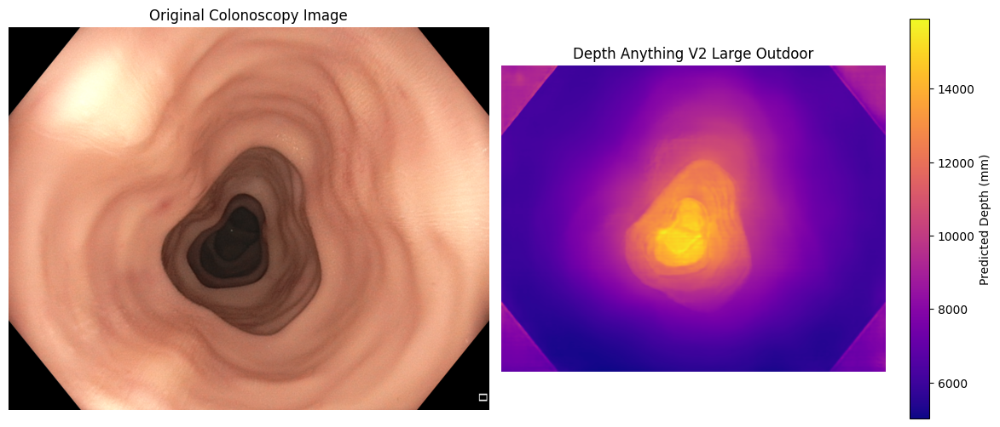

Prediction shape: (1080, 1350)
Minimum depth (mm): 5015.5044
Maximum depth (mm): 15911.468


In [89]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

# Load C3VD development image
image_path = "/content/C3VD/trans_t1_a/trans_t1_a/0001_color.png"

image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(image_path)

# Generate Outdoor model prediction
with torch.inference_mode():
    predicted_outdoor = model_outdoor.infer_image(
        image,
        input_size=518
    )

# Convert meters to millimeters
predicted_outdoor_mm = predicted_outdoor * 1000.0

# Display results
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb)
plt.title("Original Colonoscopy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(predicted_outdoor_mm, cmap="plasma")
plt.title("Depth Anything V2 Large Outdoor")
plt.colorbar(label="Predicted Depth (mm)")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Prediction shape:", predicted_outdoor_mm.shape)
print("Minimum depth (mm):", predicted_outdoor_mm.min())
print("Maximum depth (mm):", predicted_outdoor_mm.max())

In [90]:
import os
import cv2
import numpy as np
import torch

dev_folder = "/content/C3VD/trans_t1_a/trans_t1_a"

outdoor_dev_output = "/content/C3VD/outdoor_dev_predictions"
os.makedirs(outdoor_dev_output, exist_ok=True)

image_files = sorted([
    f for f in os.listdir(dev_folder)
    if f.endswith("_color.png")
])

print("Total development images:", len(image_files))

model_outdoor.eval()

for i, filename in enumerate(image_files):

    image = cv2.imread(
        os.path.join(dev_folder, filename)
    )

    if image is None:
        raise RuntimeError(f"Cannot load {filename}")

    with torch.inference_mode():
        prediction = model_outdoor.infer_image(
            image,
            input_size=518
        )

    output_name = filename.replace(
        "_color.png", "_pred.npy"
    )

    # Save raw predictions in meters
    np.save(
        os.path.join(outdoor_dev_output, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(image_files):
        print(f"Processed {i + 1}/{len(image_files)}")

print("All Large Outdoor development predictions saved!")

Total development images: 61
Processed 10/61
Processed 20/61
Processed 30/61
Processed 40/61
Processed 50/61
Processed 60/61
Processed 61/61
All Large Outdoor development predictions saved!


In [91]:
import os
import cv2
import numpy as np
from sklearn.linear_model import LinearRegression

X_outdoor = []
y_outdoor = []

prediction_files_outdoor = sorted([
    f for f in os.listdir(outdoor_dev_output)
    if f.endswith("_pred.npy")
])

for filename in prediction_files_outdoor:

    # Load Outdoor prediction (meters)
    pred = np.load(
        os.path.join(outdoor_dev_output, filename)
    )

    # Load corresponding ground-truth depth
    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {gt_filename}")

    # Convert ground truth to millimeters
    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Same valid-pixel mask as previous models
    valid = gt_raw > 0

    # Convert Outdoor prediction to millimeters
    pred_mm = pred * 1000.0

    X_outdoor.append(pred_mm[valid].reshape(-1, 1))
    y_outdoor.append(gt_mm[valid])

X_outdoor = np.concatenate(X_outdoor)
y_outdoor = np.concatenate(y_outdoor)

# Fit linear regression
outdoor_calibrator = LinearRegression()
outdoor_calibrator.fit(X_outdoor, y_outdoor)

outdoor_scale = float(outdoor_calibrator.coef_[0])
outdoor_offset = float(outdoor_calibrator.intercept_)

print("LARGE OUTDOOR CALIBRATION")
print("-------------------------")
print("Development frames:", len(prediction_files_outdoor))
print("Valid pixels:", len(y_outdoor))
print("Scale:", outdoor_scale)
print("Offset:", outdoor_offset)
print("Calibration completed!")

LARGE OUTDOOR CALIBRATION
-------------------------
Development frames: 61
Valid pixels: 82713011
Scale: 0.007487837690860033
Offset: -34.026344299316406
Calibration completed!


In [92]:
import os
import cv2
import numpy as np

mae_outdoor = []
absrel_outdoor = []
sqerr_outdoor = []
delta_outdoor = []

for filename in prediction_files_outdoor:

    # Load Outdoor prediction (meters)
    pred = np.load(
        os.path.join(outdoor_dev_output, filename)
    )

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(dev_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Convert meters to millimeters and apply calibration
    pred_mm = np.clip(
        outdoor_scale * (pred * 1000.0) + outdoor_offset,
        1e-3,
        100.0
    )

    # Same evaluation mask as previous models
    valid = gt_raw > 0

    gt = gt_mm[valid]
    prediction = pred_mm[valid]

    # MAE
    mae_outdoor.append(
        np.mean(np.abs(gt - prediction))
    )

    # AbsRel
    absrel_outdoor.append(
        np.mean(np.abs(gt - prediction) / gt)
    )

    # RMSE
    sqerr_outdoor.append(
        np.mean((gt - prediction) ** 2)
    )

    # Delta < 1.25
    ratio = np.maximum(
        gt / prediction,
        prediction / gt
    )

    delta_outdoor.append(
        np.mean(ratio < 1.25)
    )

print("LARGE OUTDOOR — DEVELOPMENT RESULTS")
print("------------------------------------")
print("MAE (mm):", round(np.mean(mae_outdoor), 4))
print("AbsRel:", round(np.mean(absrel_outdoor), 4))
print("RMSE (mm):", round(np.sqrt(np.mean(sqerr_outdoor)), 4))
print("Delta < 1.25:", round(np.mean(delta_outdoor), 4))

LARGE OUTDOOR — DEVELOPMENT RESULTS
------------------------------------
MAE (mm): 6.677
AbsRel: 0.4046
RMSE (mm): 8.2276
Delta < 1.25: 0.3874


In [93]:
import os
import cv2
import numpy as np
import torch

test_folder = "/content/C3VD/trans_t2_b/trans_t2_b"
outdoor_test_output = "/content/C3VD/outdoor_test_predictions"

os.makedirs(outdoor_test_output, exist_ok=True)

test_files = sorted([
    f for f in os.listdir(test_folder)
    if f.endswith("_color.png")
])

print("Total test images:", len(test_files))

model_outdoor.eval()

for i, filename in enumerate(test_files):

    image = cv2.imread(
        os.path.join(test_folder, filename)
    )

    if image is None:
        raise RuntimeError(f"Cannot load {filename}")

    with torch.inference_mode():
        prediction = model_outdoor.infer_image(
            image,
            input_size=518
        )

    output_name = filename.replace(
        "_color.png", "_pred.npy"
    )

    # Save raw predictions in meters
    np.save(
        os.path.join(outdoor_test_output, output_name),
        prediction.astype(np.float32)
    )

    if (i + 1) % 10 == 0 or i + 1 == len(test_files):
        print(f"Processed {i + 1}/{len(test_files)}")

print("All Large Outdoor test predictions saved!")

Total test images: 103
Processed 10/103
Processed 20/103
Processed 30/103
Processed 40/103
Processed 50/103
Processed 60/103
Processed 70/103
Processed 80/103
Processed 90/103
Processed 100/103
Processed 103/103
All Large Outdoor test predictions saved!


In [94]:
import os
import cv2
import numpy as np

mae_outdoor_test = []
absrel_outdoor_test = []
sqerr_outdoor_test = []
delta_outdoor_test = []

prediction_files_outdoor_test = sorted([
    f for f in os.listdir(outdoor_test_output)
    if f.endswith("_pred.npy")
])

for filename in prediction_files_outdoor_test:

    pred = np.load(
        os.path.join(outdoor_test_output, filename)
    )

    gt_filename = filename.replace("_pred.npy", "_depth.tiff")

    gt_raw = cv2.imread(
        os.path.join(test_folder, gt_filename),
        cv2.IMREAD_UNCHANGED
    )

    if gt_raw is None:
        raise RuntimeError(f"Cannot load {gt_filename}")

    # Convert ground truth to millimeters
    gt_mm = gt_raw.astype(np.float32) / 65535.0 * 100.0

    # Apply calibration learned from development data
    pred_mm = np.clip(
        outdoor_scale * (pred * 1000.0) + outdoor_offset,
        1e-3,
        100.0
    )

    # Same valid-pixel mask as previous models
    valid = gt_raw > 0

    gt = gt_mm[valid]
    prediction = pred_mm[valid]

    # MAE
    mae_outdoor_test.append(
        np.mean(np.abs(gt - prediction))
    )

    # AbsRel
    absrel_outdoor_test.append(
        np.mean(np.abs(gt - prediction) / gt)
    )

    # RMSE
    sqerr_outdoor_test.append(
        np.mean((gt - prediction) ** 2)
    )

    # Delta < 1.25
    ratio = np.maximum(
        gt / prediction,
        prediction / gt
    )

    delta_outdoor_test.append(
        np.mean(ratio < 1.25)
    )

print("DEPTH ANYTHING V2 LARGE OUTDOOR — TEST RESULTS")
print("-" * 55)
print("Test frames:", len(prediction_files_outdoor_test))
print("MAE (mm):", round(np.mean(mae_outdoor_test), 4))
print("AbsRel:", round(np.mean(absrel_outdoor_test), 4))
print("RMSE (mm):", round(np.sqrt(np.mean(sqerr_outdoor_test)), 4))
print("Delta < 1.25:", round(np.mean(delta_outdoor_test), 4))

DEPTH ANYTHING V2 LARGE OUTDOOR — TEST RESULTS
-------------------------------------------------------
Test frames: 103
MAE (mm): 5.8892
AbsRel: 0.3146
RMSE (mm): 7.7711
Delta < 1.25: 0.4456


In [95]:
import os
import json
import shutil
import numpy as np

save_outdoor = (
    "/content/drive/MyDrive/"
    "BN5211_Depth_Project/DepthAnythingV2/Large_Outdoor"
)

os.makedirs(save_outdoor, exist_ok=True)

# Save development and test predictions
for source, folder_name in [
    (outdoor_dev_output, "dev_predictions"),
    (outdoor_test_output, "test_predictions")
]:
    shutil.copytree(
        source,
        os.path.join(save_outdoor, folder_name),
        dirs_exist_ok=True
    )

# Save calibration and evaluation results
outdoor_results = {
    "model": "Depth Anything V2 Large Outdoor",
    "encoder": "vitl",
    "development_sequence": "trans_t1_a",
    "test_sequence": "trans_t2_b",
    "scale": float(outdoor_scale),
    "offset": float(outdoor_offset),
    "MAE_mm": float(np.mean(mae_outdoor_test)),
    "AbsRel": float(np.mean(absrel_outdoor_test)),
    "RMSE_mm": float(np.sqrt(np.mean(sqerr_outdoor_test))),
    "Delta_1.25": float(np.mean(delta_outdoor_test)),
    "valid_mask": "gt_raw > 0",
    "input_size": 518
}

with open(
    os.path.join(save_outdoor, "outdoor_results.json"), "w"
) as f:
    json.dump(outdoor_results, f, indent=4)

print("Large Outdoor results saved successfully!")
print("Location:", save_outdoor)

Large Outdoor results saved successfully!
Location: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/Large_Outdoor


In [96]:
import os
import pandas as pd

save_folder = (
    "/content/drive/MyDrive/"
    "BN5211_Depth_Project/DepthAnythingV2"
)

os.makedirs(save_folder, exist_ok=True)

data = [
    ["Constant Median", 12.9760, 0.5655, 21.2086, 0.2704],
    ["Small + Linear", 6.4007, 0.3700, 8.7136, 0.4162],
    ["Small + Smooth Correction", 4.6530, 0.2825, 5.8733, 0.5444],
    ["Large + Linear", 5.0184, 0.2838, 7.2077, 0.5531],
    ["Large Indoor + Linear", 5.4559, 0.2676, 7.7213, 0.4800],
    ["Large Outdoor + Linear", 5.8892, 0.3146, 7.7711, 0.4456]
]

df = pd.DataFrame(
    data,
    columns=[
        "Model",
        "MAE_mm",
        "AbsRel",
        "RMSE_mm",
        "Delta_1.25"
    ]
)

save_path = os.path.join(
    save_folder,
    "all_models_comparison.csv"
)

df.to_csv(save_path, index=False)

print(df.to_string(index=False))
print("\nSaved to:", save_path)

                    Model  MAE_mm  AbsRel  RMSE_mm  Delta_1.25
          Constant Median 12.9760  0.5655  21.2086      0.2704
           Small + Linear  6.4007  0.3700   8.7136      0.4162
Small + Smooth Correction  4.6530  0.2825   5.8733      0.5444
           Large + Linear  5.0184  0.2838   7.2077      0.5531
    Large Indoor + Linear  5.4559  0.2676   7.7213      0.4800
   Large Outdoor + Linear  5.8892  0.3146   7.7711      0.4456

Saved to: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/all_models_comparison.csv


# Novelty:  Specular-reliability-weighted illumination correction — DAv2 Small + Smooth

The reference is the frozen Depth Anything V2 Small model with the group's saved smooth depth-dependent bias correction. This experiment fits additional illumination-based residual corrections using development data only. The earlier global-linear novelty results are a separate experiment. This is a follow-up analysis after prior test inspection; do not describe the test as untouched for the overall project.

In [97]:
from pathlib import Path
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

ROOT = Path("/content/drive/MyDrive/BN5211_Depth_Project")
DATA = Path("/content/C3VD")
DA2_RESULTS = ROOT / "DepthAnythingV2"

OUT = DA2_RESULTS / "specular_illumination_smooth"
OUT.mkdir(parents=True, exist_ok=True)
print("Specular output directory:", OUT)

def find_file(name):
    candidates = [
        DA2_RESULTS / name,
        ROOT / "results" / name,
        ROOT / name,
        DATA / name
    ]
    for p in candidates:
        if p.is_file():
            return p
    raise FileNotFoundError(
        f"{name} not found. Set its actual path explicitly."
    )

PARAM_PATH = find_file("final_model_parameters.json")

with open(PARAM_PATH) as f:
    smooth_params = json.load(f)

assert smooth_params["model"] == "Depth Anything V2 Small"
assert smooth_params["improvement"] == (
    "Smooth Depth-Dependent Bias Correction"
)

smooth_scale = float(smooth_params["scale"])
smooth_offset = float(smooth_params["offset"])
smooth_centers = np.asarray(
    smooth_params["bin_centers_mm"], dtype=np.float64
)
smooth_values = np.asarray(
    smooth_params["correction_values_mm"], dtype=np.float64
)

def smooth_reference(pred):
    linear = np.clip(
        -smooth_scale * np.asarray(pred, dtype=np.float64)
        + smooth_offset,
        1e-3, 100.0
    )
    correction = np.interp(
        linear, smooth_centers, smooth_values
    )
    return np.clip(
        linear + correction, 1e-3, 100.0
    ).astype(np.float32)

print("Selected model: DAv2 Small + Smooth")
print("Parameters:", PARAM_PATH)
print("Scale:", smooth_scale)
print("Offset:", smooth_offset)
print("Output:", OUT)

# Check reference parameters before fitting any novelty model.
assert len(smooth_centers) == len(smooth_values) == 4
assert np.all(np.diff(smooth_centers) > 0)
assert smooth_params.get("development_dataset") == "trans_t1_a"
assert smooth_params.get("test_dataset") == "trans_t2_b"

Specular output directory: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/specular_illumination_smooth
Selected model: DAv2 Small + Smooth
Parameters: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/final_model_parameters.json
Scale: 14.802687644958496
Offset: 69.5309829711914
Output: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/specular_illumination_smooth


In [98]:
def find_prediction_dir(split):
    name = (
        "dev_predictions"
        if split == "dev" else "test_predictions"
    )

    candidates = [
        DATA / name,
        DA2_RESULTS / name,
        ROOT / name
    ]

    for folder in candidates:
        if folder.exists() and list(folder.glob("*_pred.npy")):
            return folder

    raise FileNotFoundError(
        f"Missing {name}. Update the path to saved DAv2 "
        "Small predictions."
    )

DEV_PRED = find_prediction_dir("dev")
TEST_PRED = find_prediction_dir("test")

def make_records(sequence, pred_dir):
    folder = DATA / sequence / sequence
    if not folder.exists():
        folder = DATA / sequence

    records = []

    for rgb_path in sorted(folder.glob("*_color.png")):
        stem = rgb_path.name.replace("_color.png", "")
        gt_path = folder / f"{stem}_depth.tiff"
        pred_path = pred_dir / f"{stem}_pred.npy"

        if not gt_path.exists() or not pred_path.exists():
            raise FileNotFoundError(
                f"Missing paired file for frame {stem}"
            )

        records.append((
            stem, pred_path, rgb_path, gt_path
        ))

    return records

dev_records = make_records("trans_t1_a", DEV_PRED)
test_records = make_records("trans_t2_b", TEST_PRED)

assert len(dev_records) == 61
assert len(test_records) == 103

print("Development:", len(dev_records))
print("Test:", len(test_records))
print("Depth encoding: uint16 scaled to 0-100 mm")

# Confirm the prediction folders are the Small-model folders.
# If another model also has files with these names, explicitly set
# DEV_PRED and TEST_PRED to the Small-only prediction folders.
print("Small dev prediction directory:", DEV_PRED)
print("Small test prediction directory:", TEST_PRED)


Development: 61
Test: 103
Depth encoding: uint16 scaled to 0-100 mm
Small dev prediction directory: /content/C3VD/dev_predictions
Small test prediction directory: /content/C3VD/test_predictions


In [99]:
def image_features(rgb):
    x = rgb.astype(np.float32) / 255.0

    lin = np.where(
        x <= 0.04045,
        x / 12.92,
        ((x + 0.055) / 1.055) ** 2.4
    )

    luminance = (
        0.2126 * lin[..., 0] +
        0.7152 * lin[..., 1] +
        0.0722 * lin[..., 2]
    )

    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    sat = hsv[..., 1].astype(np.float32) / 255.0
    val = hsv[..., 2].astype(np.float32) / 255.0

    specular = (val > 0.92) & (sat < 0.26)
    shadow = val < 0.10

    bright_gate = np.clip((0.97 - val) / 0.12, 0, 1)
    dark_gate = np.clip((val - 0.08) / 0.15, 0, 1)

    reliability = bright_gate * dark_gate
    reliability[specular | shadow] = 0.0

    rgb_valid = np.max(rgb, axis=2) > 10
    median_lum = float(np.median(luminance[rgb_valid])) if rgb_valid.any() else 1.0
    normalized = luminance / max(median_lum, 1e-3)

    brightness = 1.0 / np.sqrt(
        np.maximum(normalized, 1e-3)
    )

    h, w = luminance.shape
    yy, xx = np.indices((h, w), dtype=np.float32)

    radius = np.sqrt(
        ((xx - (w - 1)/2) / (w/2))**2 +
        ((yy - (h - 1)/2) / (h/2))**2
    ) / np.sqrt(2)

    return (
        brightness.astype(np.float32),
        reliability.astype(np.float32),
        specular,
        shadow,
        np.clip(radius, 0, 1).astype(np.float32)
    )

def load_record(record):
    stem, pred_path, rgb_path, gt_path = record

    bgr = cv2.imread(str(rgb_path))
    raw = cv2.imread(
        str(gt_path), cv2.IMREAD_UNCHANGED
    )

    if bgr is None or raw is None:
        raise FileNotFoundError(stem)

    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    pred = np.load(pred_path).astype(np.float32)
    gt = raw.astype(np.float32) * (100.0 / 65535.0)

    if pred.shape != gt.shape or rgb.shape[:2] != gt.shape:
        raise ValueError(f"Frame {stem}: prediction, GT and RGB shapes differ")

    valid = (
        (raw > 0) &
        (raw < 65535) &
        (rgb.max(axis=2) > 10) &
        np.isfinite(pred)
    )

    brightness, rel, spec, shadow, radius = (
        image_features(rgb)
    )

    return {
        "frame": stem,
        "rgb": rgb,
        "pred": pred,
        "gt": gt,
        "valid": valid,
        "brightness": brightness,
        "reliability": rel,
        "specular": spec,
        "shadow": shadow,
        "radius": radius
    }

print("Features loaded:", load_record(dev_records[0])["frame"])

# Development-frame sanity check only (no test GT inspection).
example = load_record(dev_records[0])
print("Example:", example["frame"], "shape:", example["pred"].shape,
      "valid fraction:", float(example["valid"].mean()))


Features loaded: 0000
Example: 0000 shape: (1080, 1350) valid fraction: 0.9106378600823045


In [100]:
MODES = {
    "A: Small + Smooth": "base",
    "B: + Brightness": "brightness",
    "C: + Reliability": "weighted",
    "D: + Combined": "combined"
}

def design_matrix(base, brightness, reliability, radius, mode, idx=None):
    # When idx is supplied, build features only for sampled pixels.
    d = np.asarray(base).ravel()
    b = np.asarray(brightness).ravel()
    w = np.asarray(reliability).ravel()
    r = np.asarray(radius).ravel()
    if idx is not None:
        d, b, w, r = d[idx], b[idx], w[idx], r[idx]
    d, b, w, r = [v.astype(np.float64, copy=False) for v in (d,b,w,r)]
    # Radius is a common nuisance feature for fair comparisons.
    if mode == "brightness":
        cols = [b, r]
    elif mode == "weighted":
        cols = [w*b, w, r]
    elif mode == "combined":
        cols = [b, w*b, w, w*b*d, r]
    else:
        raise ValueError(mode)
    return np.column_stack(cols)

def make_samples(records, seed=42, pixels_per_frame=2500):
    rng = np.random.default_rng(seed)
    compact = []
    for rec in records:
        item = load_record(rec)
        base = smooth_reference(item["pred"])
        valid_idx = np.flatnonzero(item["valid"].ravel())
        if not len(valid_idx):
            raise ValueError(f"No valid pixels: {item['frame']}")
        idx = rng.choice(valid_idx, size=min(pixels_per_frame, len(valid_idx)), replace=False)
        compact.append({
            "base": base.ravel()[idx],
            "brightness": item["brightness"].ravel()[idx],
            "reliability": item["reliability"].ravel()[idx],
            "radius": item["radius"].ravel()[idx],
            "target": (item["gt"] - base).ravel()[idx]
        })
    return compact

def fit_variant(samples, mode, alpha):
    if mode == "base":
        return None
    X_parts, y_parts = [], []
    for sample in samples:
        X_parts.append(design_matrix(sample["base"], sample["brightness"],
                                     sample["reliability"], sample["radius"], mode))
        y_parts.append(sample["target"].astype(np.float64))
    reg = make_pipeline(StandardScaler(), Ridge(alpha=float(alpha)))
    reg.fit(np.concatenate(X_parts), np.concatenate(y_parts))
    return reg

def predict_variant(reg, item, mode, chunk=200000):
    base = smooth_reference(item["pred"])
    if mode == "base":
        return base
    residual = np.empty(base.size, dtype=np.float32)
    # Chunk inference so 1080x1350 frames do not require a huge
    # float64 design matrix in Colab memory.
    for lo in range(0, base.size, chunk):
        idx = np.arange(lo, min(lo+chunk, base.size))
        X = design_matrix(base, item["brightness"],
                          item["reliability"], item["radius"], mode, idx=idx)
        residual[lo:lo+len(idx)] = reg.predict(X).astype(np.float32)
    residual = residual.reshape(base.shape)
    # Brightness-only is intentionally not reliability-gated.
    correction = residual if mode == "brightness" else item["reliability"] * residual
    return np.clip(base + correction, 1e-3, 100.0).astype(np.float32)

def metrics(gt, pred, mask):
    g = gt[mask].astype(np.float64)
    p = np.clip(
        pred[mask].astype(np.float64),
        1e-3, 100.0
    )

    if len(g) == 0:
        raise ValueError("No valid pixels")

    error = p - g

    return {
        "MAE_mm": float(np.mean(np.abs(error))),
        "AbsRel": float(np.mean(np.abs(error) / g)),
        "MSE_mm2": float(np.mean(error ** 2)),
        "Delta1": float(np.mean(
            np.maximum(p/g, g/p) < 1.25
        ))
    }

print("Smooth-based specular ablations ready.")

Smooth-based specular ablations ready.


In [101]:

import time
import gc
import numpy as np
import pandas as pd

ALPHAS = [1.0, 100.0, 10000.0]

def temporal_folds(n, blocks=4, gap=2):
    folds = []
    for val in np.array_split(np.arange(n), blocks):
        excluded = np.arange(
            max(0, val[0] - gap),
            min(n, val[-1] + gap + 1)
        )
        train = np.setdiff1d(np.arange(n), excluded)
        folds.append((train, val))
    return folds

folds = temporal_folds(len(dev_records), 4, 2)
cv_rows = []

for fold_id, (train_idx, val_idx) in enumerate(folds):
    print(f"\nPreparing fold {fold_id+1}/4...", flush=True)

    # Load training samples only once per fold
    samples = make_samples(
        [dev_records[int(i)] for i in train_idx]
    )

    for label, mode in MODES.items():
        alpha_values = (
            [ALPHAS[0]] if mode == "base" else ALPHAS
        )

        for alpha in alpha_values:
            start = time.time()
            reg = fit_variant(samples, mode, alpha)

            values = []

            for j in val_idx:
                item = load_record(dev_records[int(j)])
                pred = predict_variant(reg, item, mode)

                values.append(
                    metrics(item["gt"], pred, item["valid"])
                )

                del item, pred

            cv_rows.append({
                "alpha": alpha,
                "method": label,
                "fold": fold_id,
                "AbsRel": np.mean(
                    [v["AbsRel"] for v in values]
                ),
                "MSE_mm2": np.mean(
                    [v["MSE_mm2"] for v in values]
                ),
                "Delta1": np.mean(
                    [v["Delta1"] for v in values]
                )
            })

            print(
                f"Fold {fold_id+1}/4 | {label} | "
                f"alpha={alpha} | "
                f"{time.time()-start:.1f}s",
                flush=True
            )

            del reg, values
            gc.collect()

    del samples
    gc.collect()

cv_df = pd.DataFrame(cv_rows)

tuning = cv_df[
    cv_df["method"] != "A: Small + Smooth"
]

chosen_alpha = float(
    tuning.groupby("alpha")["AbsRel"].mean().idxmin()
)

cv_df.to_csv(
    OUT / "development_cv.csv",
    index=False
)

print("\nChosen alpha:", chosen_alpha)
print(
    cv_df.groupby(["method", "alpha"])[
        ["AbsRel", "MSE_mm2", "Delta1"]
    ].mean().round(4)
)
print("\nCross-validation completed.")



Preparing fold 1/4...
Fold 1/4 | A: Small + Smooth | alpha=1.0 | 4.7s
Fold 1/4 | B: + Brightness | alpha=1.0 | 5.3s
Fold 1/4 | B: + Brightness | alpha=100.0 | 6.2s
Fold 1/4 | B: + Brightness | alpha=10000.0 | 5.1s
Fold 1/4 | C: + Reliability | alpha=1.0 | 7.9s
Fold 1/4 | C: + Reliability | alpha=100.0 | 6.2s
Fold 1/4 | C: + Reliability | alpha=10000.0 | 8.0s
Fold 1/4 | D: + Combined | alpha=1.0 | 6.8s
Fold 1/4 | D: + Combined | alpha=100.0 | 8.5s
Fold 1/4 | D: + Combined | alpha=10000.0 | 6.6s

Preparing fold 2/4...
Fold 2/4 | A: Small + Smooth | alpha=1.0 | 4.5s
Fold 2/4 | B: + Brightness | alpha=1.0 | 5.6s
Fold 2/4 | B: + Brightness | alpha=100.0 | 4.8s
Fold 2/4 | B: + Brightness | alpha=10000.0 | 6.2s
Fold 2/4 | C: + Reliability | alpha=1.0 | 5.8s
Fold 2/4 | C: + Reliability | alpha=100.0 | 6.9s
Fold 2/4 | C: + Reliability | alpha=10000.0 | 6.1s
Fold 2/4 | D: + Combined | alpha=1.0 | 7.3s
Fold 2/4 | D: + Combined | alpha=100.0 | 6.8s
Fold 2/4 | D: + Combined | alpha=10000.0 | 7.2s


In [102]:

samples = make_samples(dev_records)

fitted = {
    label: fit_variant(samples, mode, chosen_alpha)
    for label, mode in MODES.items()
}

dev_valid_depths = []

for rec in dev_records:
    item = load_record(rec)
    dev_valid_depths.append(
        item["gt"][item["valid"]]
    )

constant_median = float(
    np.median(np.concatenate(dev_valid_depths))
)

print("Development frames:", len(dev_records))
print("Development median:", constant_median)
print("Selected alpha:", chosen_alpha)
print("All correction models fitted.")


Development frames: 61
Development median: 17.259479522705078
Selected alpha: 10000.0
All correction models fitted.


In [103]:
rows = []
region_rows = []

for rec in test_records:
    item = load_record(rec)
    valid = item["valid"]

    predictions = {
        "Constant median": np.full_like(
            item["gt"], constant_median
        )
    }

    for label, mode in MODES.items():
        predictions[label] = predict_variant(
            fitted[label], item, mode
        )

    regions = {
        "Specular": valid & item["specular"],
        "Shadow": valid & item["shadow"],
        "Other": valid & ~(
            item["specular"] | item["shadow"]
        )
    }

    for name, pred in predictions.items():
        rows.append({
            "frame": item["frame"],
            "method": name,
            "mask": "A",
            **metrics(item["gt"], pred, valid)
        })

        for region, region_mask in regions.items():
            if not region_mask.any():
                continue

            region_rows.append({
                "frame": item["frame"],
                "method": name,
                "region": region,
                "fraction": float(
                    region_mask.sum() / valid.sum()
                ),
                **metrics(item["gt"], pred, region_mask)
            })

per_frame = pd.DataFrame(rows)
regions_df = pd.DataFrame(region_rows)

summary = (
    per_frame.groupby("method")
    .agg(
        MAE_mm=("MAE_mm", "mean"),
        AbsRel=("AbsRel", "mean"),
        MSE_mm2=("MSE_mm2", "mean"),
        Delta1=("Delta1", "mean"),
        n_frames=("frame", "nunique")
    )
    .reset_index()
)

summary["RMSE_mm"] = np.sqrt(summary["MSE_mm2"])
summary["Mask"] = "A"

region_summary = (
    regions_df.groupby(["method", "region"])
    .agg(
        AbsRel=("AbsRel", "mean"),
        MSE_mm2=("MSE_mm2", "mean"),
        fraction=("fraction", "mean"),
        n_frames=("frame", "nunique")
    )
    .reset_index()
)

region_summary["RMSE_mm"] = np.sqrt(
    region_summary["MSE_mm2"]
)

per_frame.to_csv(
    OUT / "specular_per_frame_mask_A.csv",
    index=False
)
summary.to_csv(
    OUT / "specular_summary_mask_A.csv",
    index=False
)
regions_df.to_csv(
    OUT / "specular_regions_per_frame.csv",
    index=False
)
region_summary.to_csv(
    OUT / "specular_regions_summary.csv",
    index=False
)

assert per_frame.groupby("method")["frame"].nunique().eq(103).all()
print("FINAL TEST RESULTS")
print(
    summary[
        ["method", "MAE_mm", "AbsRel",
         "RMSE_mm", "Delta1", "n_frames"]
    ].round(4).to_string(index=False)
)

print("\nREGION ANALYSIS")
print(region_summary.round(4).to_string(index=False))


FINAL TEST RESULTS
           method  MAE_mm  AbsRel  RMSE_mm  Delta1  n_frames
A: Small + Smooth  4.4100  0.2853   5.4282  0.5378       103
  B: + Brightness  4.4916  0.3029   5.4833  0.5227       103
 C: + Reliability  4.4034  0.2933   5.3476  0.5347       103
  Constant median 11.4542  0.5498  17.7105  0.2752       103
    D: + Combined  4.3870  0.2945   5.3554  0.5375       103

REGION ANALYSIS
           method   region  AbsRel   MSE_mm2  fraction  n_frames  RMSE_mm
A: Small + Smooth    Other  0.2667   30.0168    0.9290       103   5.4788
A: Small + Smooth   Shadow  0.9982   53.0954    0.0001       103   7.2867
A: Small + Smooth Specular  0.5313   22.2352    0.0709       103   4.7154
  B: + Brightness    Other  0.2805   29.8922    0.9290       103   5.4674
  B: + Brightness   Shadow  7.9833 1918.5848    0.0001       103  43.8017
  B: + Brightness Specular  0.5862   29.4238    0.0709       103   5.4244
 C: + Reliability    Other  0.2753   29.0578    0.9290       103   5.3905
 C: + 

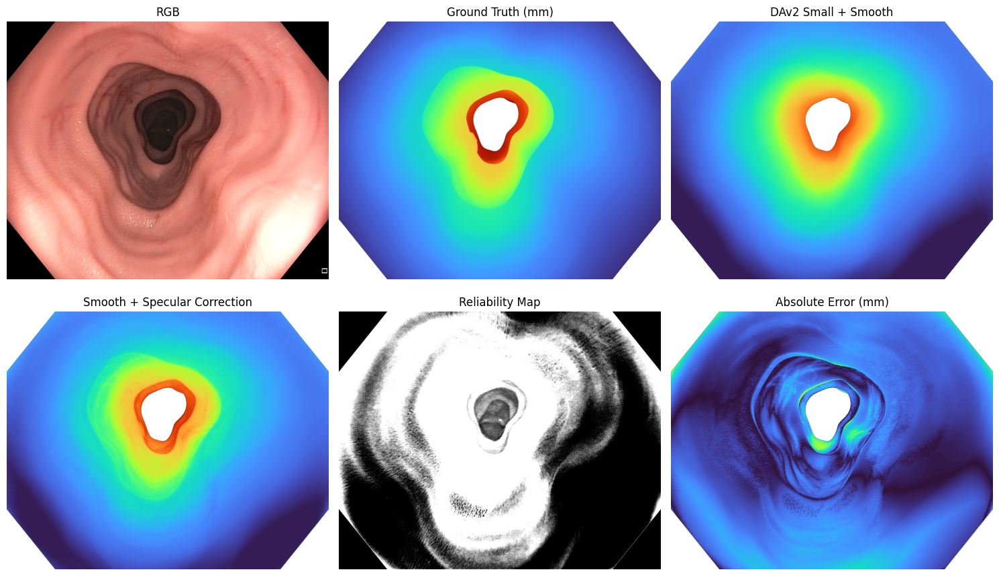

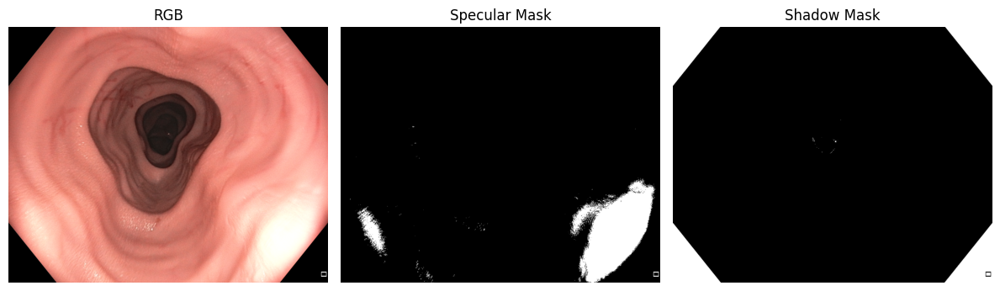

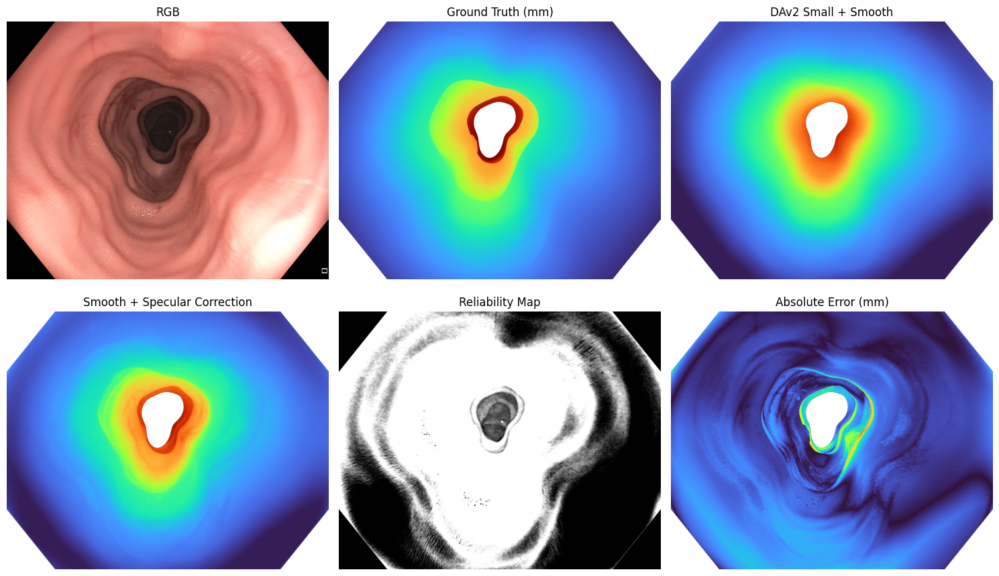

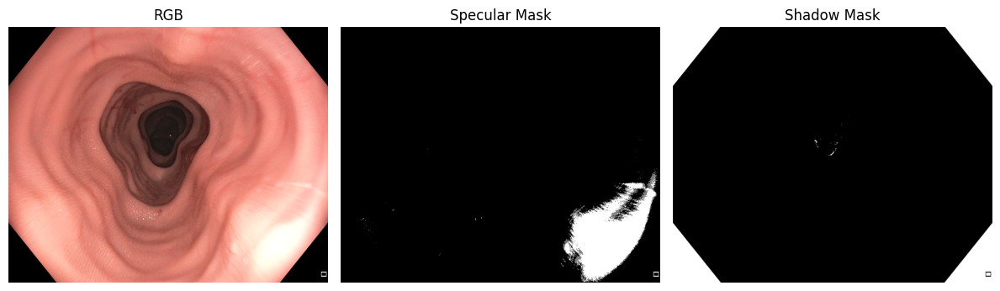

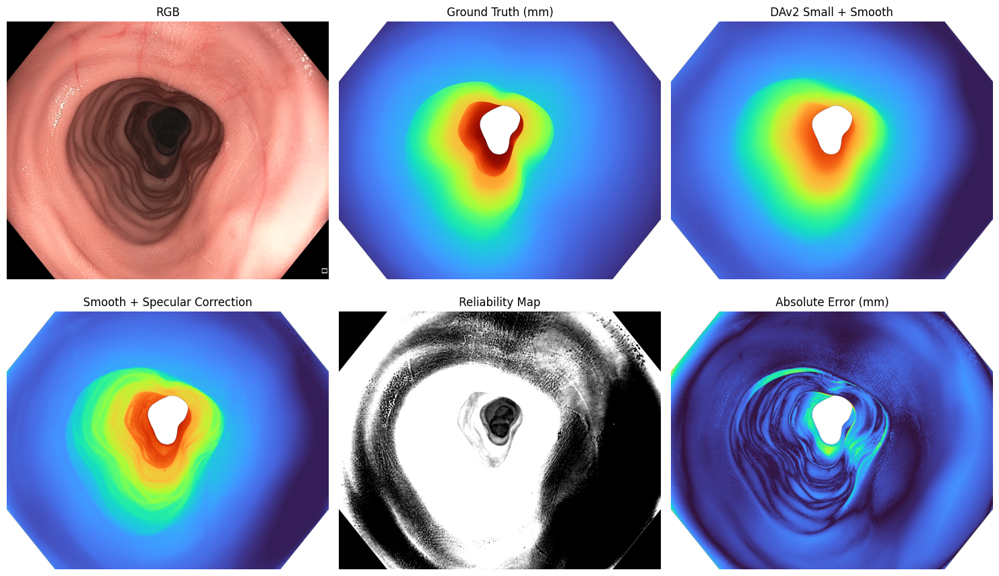

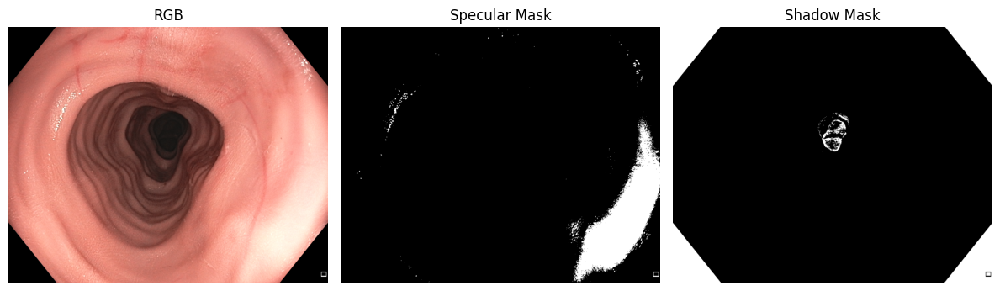

Saved figures to: /content/drive/MyDrive/BN5211_Depth_Project/DepthAnythingV2/specular_illumination_smooth


In [104]:
for k in [0, len(test_records)//2, len(test_records)-1]:
    item = load_record(test_records[k])

    reference = predict_variant(
        None, item, "base"
    )
    combined = predict_variant(
        fitted["D: + Combined"],
        item, "combined"
    )

    valid = item["valid"]

    panels = [
        item["rgb"],
        np.where(valid, item["gt"], np.nan),
        np.where(valid, reference, np.nan),
        np.where(valid, combined, np.nan),
        item["reliability"],
        np.where(
            valid,
            np.abs(combined - item["gt"]),
            np.nan
        )
    ]

    titles = [
        "RGB",
        "Ground Truth (mm)",
        "DAv2 Small + Smooth",
        "Smooth + Specular Correction",
        "Reliability Map",
        "Absolute Error (mm)"
    ]

    fig, axes = plt.subplots(2, 3, figsize=(15, 9))

    for ax, panel, title in zip(axes.flat, panels, titles):
        if title == "RGB":
            ax.imshow(panel)
        elif title == "Reliability Map":
            ax.imshow(panel, cmap="gray", vmin=0, vmax=1)
        else:
            vmax = 40 if "Error" in title else 100
            ax.imshow(
                panel, cmap="turbo", vmin=0, vmax=vmax
            )
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(
        OUT / f"comparison_{item['frame']}.png",
        dpi=160, bbox_inches="tight"
    )
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(item["rgb"])
    axes[0].set_title("RGB")
    axes[1].imshow(item["specular"], cmap="gray")
    axes[1].set_title("Specular Mask")
    axes[2].imshow(item["shadow"], cmap="gray")
    axes[2].set_title("Shadow Mask")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(
        OUT / f"masks_{item['frame']}.png",
        dpi=160, bbox_inches="tight"
    )
    plt.show()

print("Saved figures to:", OUT)


In [105]:

from pathlib import Path
import pandas as pd
import numpy as np

required = [
    "development_cv.csv",
    "specular_per_frame_mask_A.csv",
    "specular_summary_mask_A.csv",
    "specular_regions_per_frame.csv",
    "specular_regions_summary.csv"
]

for name in required:
    path = OUT / name
    assert path.exists(), f"Missing: {path}"
    assert path.stat().st_size > 0, f"Empty: {path}"
    print("FOUND:", name)

summary = pd.read_csv(
    OUT / "specular_summary_mask_A.csv"
)

frames = pd.read_csv(
    OUT / "specular_per_frame_mask_A.csv"
)

expected = {
    "Constant median",
    "A: Small + Smooth",
    "B: + Brightness",
    "C: + Reliability",
    "D: + Combined"
}

assert set(summary["method"]) == expected
assert len(frames) == 515

assert frames.groupby("method")["frame"].nunique().eq(103).all()

cols = ["MAE_mm", "AbsRel", "RMSE_mm", "Delta1"]
assert np.isfinite(summary[cols].to_numpy()).all()

print("\nFINAL RESULTS")
print(
    summary[["method"] + cols]
    .round(4)
    .to_string(index=False)
)

base = summary.set_index("method").loc["A: Small + Smooth"]

for name in [
    "B: + Brightness",
    "C: + Reliability",
    "D: + Combined"
]:
    result = summary.set_index("method").loc[name]

    rmse_gain = 100 * (
        base["RMSE_mm"] - result["RMSE_mm"]
    ) / base["RMSE_mm"]

    absrel_gain = 100 * (
        base["AbsRel"] - result["AbsRel"]
    ) / base["AbsRel"]

    delta_gain = 100 * (
        result["Delta1"] - base["Delta1"]
    )

    print(f"\n{name}")
    print(f"RMSE reduction: {rmse_gain:+.2f}%")
    print(f"AbsRel reduction: {absrel_gain:+.2f}%")
    print(f"Delta improvement: {delta_gain:+.2f} pp")

print("\nVerification completed.")


FOUND: development_cv.csv
FOUND: specular_per_frame_mask_A.csv
FOUND: specular_summary_mask_A.csv
FOUND: specular_regions_per_frame.csv
FOUND: specular_regions_summary.csv

FINAL RESULTS
           method  MAE_mm  AbsRel  RMSE_mm  Delta1
A: Small + Smooth  4.4100  0.2853   5.4282  0.5378
  B: + Brightness  4.4916  0.3029   5.4833  0.5227
 C: + Reliability  4.4034  0.2933   5.3476  0.5347
  Constant median 11.4542  0.5498  17.7105  0.2752
    D: + Combined  4.3870  0.2945   5.3554  0.5375

B: + Brightness
RMSE reduction: -1.01%
AbsRel reduction: -6.18%
Delta improvement: -1.51 pp

C: + Reliability
RMSE reduction: +1.49%
AbsRel reduction: -2.83%
Delta improvement: -0.30 pp

D: + Combined
RMSE reduction: +1.34%
AbsRel reduction: -3.24%
Delta improvement: -0.03 pp

Verification completed.


In [107]:

from pathlib import Path
import pandas as pd
import numpy as np

required = [
    "development_cv.csv",
    "specular_per_frame_mask_A.csv",
    "specular_summary_mask_A.csv",
    "specular_regions_per_frame.csv",
    "specular_regions_summary.csv"
]

for name in required:
    path = OUT / name
    assert path.exists(), f"Missing: {path}"
    assert path.stat().st_size > 0, f"Empty: {path}"
    print("FOUND:", name)

summary = pd.read_csv(
    OUT / "specular_summary_mask_A.csv"
)

frames = pd.read_csv(
    OUT / "specular_per_frame_mask_A.csv"
)

expected = {
    "Constant median",
    "A: Small + Smooth",
    "B: + Brightness",
    "C: + Reliability",
    "D: + Combined"
}

assert set(summary["method"]) == expected
assert len(frames) == 515

assert frames.groupby("method")["frame"].nunique().eq(103).all()

cols = ["MAE_mm", "AbsRel", "RMSE_mm", "Delta1"]
assert np.isfinite(summary[cols].to_numpy()).all()

print("\nFINAL RESULTS")
print(
    summary[["method"] + cols]
    .round(4)
    .to_string(index=False)
)

base = summary.set_index("method").loc["A: Small + Smooth"]

for name in [
    "B: + Brightness",
    "C: + Reliability",
    "D: + Combined"
]:
    result = summary.set_index("method").loc[name]

    rmse_gain = 100 * (
        base["RMSE_mm"] - result["RMSE_mm"]
    ) / base["RMSE_mm"]

    absrel_gain = 100 * (
        base["AbsRel"] - result["AbsRel"]
    ) / base["AbsRel"]

    delta_gain = 100 * (
        result["Delta1"] - base["Delta1"]
    )

    print(f"\n{name}")
    print(f"RMSE reduction: {rmse_gain:+.2f}%")
    print(f"AbsRel reduction: {absrel_gain:+.2f}%")
    print(f"Delta improvement: {delta_gain:+.2f} pp")

print("\nVerification completed.")


FOUND: development_cv.csv
FOUND: specular_per_frame_mask_A.csv
FOUND: specular_summary_mask_A.csv
FOUND: specular_regions_per_frame.csv
FOUND: specular_regions_summary.csv

FINAL RESULTS
           method  MAE_mm  AbsRel  RMSE_mm  Delta1
A: Small + Smooth  4.4100  0.2853   5.4282  0.5378
  B: + Brightness  4.4916  0.3029   5.4833  0.5227
 C: + Reliability  4.4034  0.2933   5.3476  0.5347
  Constant median 11.4542  0.5498  17.7105  0.2752
    D: + Combined  4.3870  0.2945   5.3554  0.5375

B: + Brightness
RMSE reduction: -1.01%
AbsRel reduction: -6.18%
Delta improvement: -1.51 pp

C: + Reliability
RMSE reduction: +1.49%
AbsRel reduction: -2.83%
Delta improvement: -0.30 pp

D: + Combined
RMSE reduction: +1.34%
AbsRel reduction: -3.24%
Delta improvement: -0.03 pp

Verification completed.


In [108]:

from pathlib import Path
import pandas as pd
import numpy as np

required = [
    "specular_summary_mask_A.csv",
    "specular_per_frame_mask_A.csv",
    "specular_regions_summary.csv",
    "specular_regions_per_frame.csv",
    "development_cv.csv"
]

for filename in required:
    path = OUT / filename
    assert path.exists(), f"Missing: {path}"
    assert path.stat().st_size > 0, f"Empty: {path}"
    print("FOUND:", filename)

summary_check = pd.read_csv(
    OUT / "specular_summary_mask_A.csv"
)

per_frame_check = pd.read_csv(
    OUT / "specular_per_frame_mask_A.csv"
)

expected_methods = {
    "Constant median",
    "A: Small + Smooth",
    "B: + Brightness",
    "C: + Reliability",
    "D: + Combined"
}

assert set(summary_check["method"]) == expected_methods
assert len(per_frame_check) == 103 * 5

assert (
    per_frame_check.groupby("method")["frame"].nunique() == 103
).all()

assert np.isfinite(
    summary_check[
        ["MAE_mm", "AbsRel", "RMSE_mm", "Delta1"]
    ].to_numpy()
).all()

print("\nNEW SMOOTH-BASED RESULTS")
print(summary_check.round(4).to_string(index=False))

print("\nAll basic output checks passed.")


FOUND: specular_summary_mask_A.csv
FOUND: specular_per_frame_mask_A.csv
FOUND: specular_regions_summary.csv
FOUND: specular_regions_per_frame.csv
FOUND: development_cv.csv

NEW SMOOTH-BASED RESULTS
           method  MAE_mm  AbsRel  MSE_mm2  Delta1  n_frames  RMSE_mm Mask
A: Small + Smooth  4.4100  0.2853  29.4654  0.5378       103   5.4282    A
  B: + Brightness  4.4916  0.3029  30.0666  0.5227       103   5.4833    A
 C: + Reliability  4.4034  0.2933  28.5963  0.5347       103   5.3476    A
  Constant median 11.4542  0.5498 313.6611  0.2752       103  17.7105    A
    D: + Combined  4.3870  0.2945  28.6803  0.5375       103   5.3554    A

All basic output checks passed.


### Interpretation and reporting checklist

- Report **all** rows, including negative results. A brightness cue can fail under the C3VD texture shift.
- This is a **regression-based post-processing calibration**, not neural-network fine-tuning. The illumination weighting is heuristic and should not be described as calibrated physical photometry.
- Report the chosen alpha, dev-block validation procedure, model checkpoint and the ground-truth TIFF decoding. The fixed `gt > 0 and gt < 100 mm` mask excludes saturated pixels.
- **Do not** compare to previous notebook tables as if protocols were identical unless the ground-truth mask, median baseline and aggregation match.
- Your earlier notebook also contains **Large** and **metric indoor/outdoor** model predictions. This extension intentionally uses **DAv2 Small** `dev_predictions` and `test_predictions` only. For MiDaS, raw MiDaS predictions must be substituted and the same pipeline rerun; it is not a MiDaS modification.
- A positive performance gain is not guaranteed. Check especially near/far depth errors and specular-region errors, and do not choose methods based on held-out test results.